In [1]:
from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.spatial import distance_matrix
from scipy.spatial import distance
from scipy.optimize import minimize
from scipy.optimize import basinhopping
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
import math
import shutil
import time
from numba import jit
import os
import statistics

In [2]:
##############################################
# To Create your platelet, you can vary the
# dimensions below. The rest of the data initialization
# section of the code does not need to be changed.
##############################################

z_dist = 5.44  #z distance between plateletes for 2 layer platelet system

percent = 0.775  #size percentage of the edge atom hexagon (<1 so the edge atoms have smaller radius)

flat_radius = 5.19  #flat plate radius

hex_radius = 5.19   #hexagon radius

theta = 61 *np.pi/180   #theta of double layer platelet system, in rad

n_rings = 3

x_dist = z_dist/np.tan(theta) #x distance shift of bottom layer based on theta
x_dist
y_dist=x_dist

In [3]:
def hexa(n_rings,radius):
    #width and height of the hexagon
    w = radius*2/np.sqrt(3)
    h = radius
    N = int(n_rings/2)

    #generate empty arrays
    central_x = []
    central_y = []
    edge_x = []
    edge_y = []

    if (n_rings%2==1):
        print("n_rings must be even number")
    else:
        #top edge atom layer
        edge_x.append(0)
        edge_y.append(0)
        for i in range(N):
            edge_x.append(edge_x[-1]+1.5*w)
            edge_y.append(edge_y[-1])

        #first half of hexagon
        for i in range(N):
            central_x.append(edge_x[0]+0.75*w)
            central_y.append(edge_y[0]-0.5*h)
            for j in range(N -1 +i):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            central_x.append(edge_x[0])
            central_y.append(edge_y[0]-h)
            for j in range(N+i):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.insert(0,edge_x[0]-0.75*w)
            edge_y.insert(0,edge_y[0]-1.5*h)
            central_x.append(edge_x[0]+1.5*w)
            central_y.append(edge_y[0])
            for j in range(N -1 +i):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.append(central_x[-1]+1.5*w)
            edge_y.append(central_y[-1])

        #second half of hexagon
        for i in range(N-1):
            central_x.append(edge_x[0]+0.75*w)
            central_y.append(edge_y[0]-0.5*h)
            for j in range(N+(N-i)-1):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            central_x.append(edge_x[0]+1.5*w)
            central_y.append(edge_y[0]-h)
            for j in range(N+(N-i)-2):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.insert(0,edge_x[0]+0.75*w)
            edge_y.insert(0,edge_y[0]-1.5*h)
            central_x.append(edge_x[0]+1.5*w)
            central_y.append(edge_y[0])
            for j in range(N +(N-i)-3):
                central_x.append(central_x[-1]+1.5*w)
                central_y.append(central_y[-1])
            edge_x.append(central_x[-1]+1.5*w)
            edge_y.append(central_y[-1])
        central_x.append(edge_x[0]+0.75*w)
        central_y.append(edge_y[0]-0.5*h)
        for j in range(N):
            central_x.append(central_x[-1]+1.5*w)
            central_y.append(central_y[-1])
        central_x.append(edge_x[0]+1.5*w)
        central_y.append(edge_y[0]-h)
        for j in range(N-1):
            central_x.append(central_x[-1]+1.5*w)
            central_y.append(central_y[-1])
        edge_x.append(edge_x[0]+0.75*w)
        edge_y.append(edge_y[0]-1.5*h)
        for i in range(N):
            edge_x.append(edge_x[-1]+1.5*w)
            edge_y.append(edge_y[-1])

        #center of mass back to 0
        edge_x -= np.average(edge_x)
        edge_y -= np.average(edge_y)
        central_x -= np.average(central_x)
        central_y -= np.average(central_y)

        #NEW - MERGE EDGE AND CENTRAL
        central_x = np.concatenate((central_x,edge_x))
        central_y = np.concatenate((central_y,edge_y))

        #NEW - EDGE ATOMS
        edge_x = []
        edge_y = []

        edge_x.append(n_rings*0.75*w+0.5*w)
        edge_y.append(0)

        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]-h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]-0.75*w)
            edge_y.append(edge_y[-1]-1.5*h)
        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]-h)

        edge_x.append(edge_x[-1]-w)
        edge_y.append(edge_y[-1])
        for i in range(N-1):
            edge_x.append(edge_x[-1]-1.5*w)
            edge_y.append(edge_y[-1])
        edge_x.append(edge_x[-1]-w)
        edge_y.append(edge_y[-1])

        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]+h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]-0.75*w)
            edge_y.append(edge_y[-1]+1.5*h)
        edge_x.append(edge_x[-1]-0.5*w)
        edge_y.append(edge_y[-1]+h)

        edge_x.append(edge_x[-1]+0.5*w)
        edge_y.append(edge_y[-1]+h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]+0.75*w)
            edge_y.append(edge_y[-1]+1.5*h)
        edge_x.append(edge_x[-1]+0.5*w)
        edge_y.append(edge_y[-1]+h)

        edge_x.append(edge_x[-1]+w)
        edge_y.append(edge_y[-1])
        for i in range(N-1):
            edge_x.append(edge_x[-1]+1.5*w)
            edge_y.append(edge_y[-1])
        edge_x.append(edge_x[-1]+w)
        edge_y.append(edge_y[-1])

        edge_x.append(edge_x[-1]+0.5*w)
        edge_y.append(edge_y[-1]-h)
        for i in range(N-1):
            edge_x.append(edge_x[-1]+0.75*w)
            edge_y.append(edge_y[-1]-1.5*h)

    return central_x,central_y,edge_x,edge_y

Total number of atoms, small platelet:  25
Long diameter, small platelet: 23.972 A: 


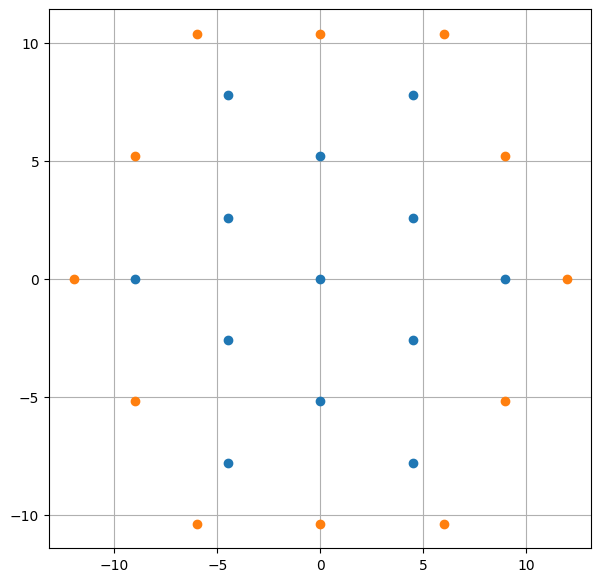

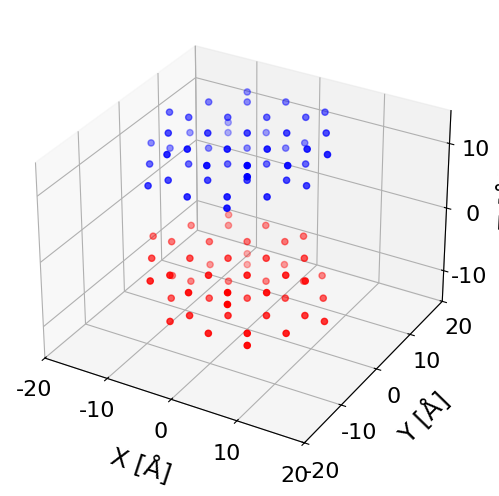

In [5]:

#create flat plate edge and central atoms for the small platelet
x,y,xx,yy = hexa(2,5.19)

#print total number of atoms
print("Total number of atoms, small platelet: ",len(x)+len(xx))
print("Long diameter, small platelet: %.3f A: " %(max(xx)-min(xx)))

z = np.zeros(len(x))
zz = np.zeros(len(xx))

#put x,y,z data into one array
CentralPlatelet = np.stack((x,y,z),axis=-1)
EdgePlatelet = np.stack((xx,yy,zz),axis=-1)

#make two platelets
CentralPlatelet2=CentralPlatelet.copy()
CentralPlatelet2[:,2]=CentralPlatelet[:,2]+z_dist
CentralPlatelet2[:,0]=CentralPlatelet[:,0]-x_dist

EdgePlatelet2=EdgePlatelet.copy()
EdgePlatelet2[:,2]=EdgePlatelet[:,2]+z_dist
EdgePlatelet2[:,0]=EdgePlatelet[:,0]-x_dist

#fit into one array
S_CentralPlate = np.vstack((CentralPlatelet,CentralPlatelet2))
S_EdgePlate = np.vstack((EdgePlatelet,EdgePlatelet2))

#plot results
plt.figure(figsize=(7,7))
plt.plot(CentralPlatelet[:,0],CentralPlatelet[:,1],"o")
plt.plot(EdgePlatelet[:,0],EdgePlatelet[:,1],"o")
plt.grid()
plt.show()





#mirror flat plate data for the large platelet
S_CentralPlateMirr=S_CentralPlate.copy()
S_CentralPlateMirr[:,2]=-S_CentralPlateMirr[:,2]
S_CentralPlateMirr[:,2]=S_CentralPlateMirr[:,2]+z_dist

S_EdgePlateMirr=S_EdgePlate.copy()
S_EdgePlateMirr[:,2]=-S_EdgePlateMirr[:,2]
S_EdgePlateMirr[:,2]=S_EdgePlateMirr[:,2]+z_dist

#plot both
fig = plt.figure(figsize=(8,6))
ax = fig.add_subplot(projection='3d')
ax.scatter(S_CentralPlate[:,0],S_CentralPlate[:,1],S_CentralPlate[:,2]-10, color = 'red', label = "Central Original Platelet")
ax.scatter(S_EdgePlate[:,0],S_EdgePlate[:,1],S_EdgePlate[:,2]-10, color = 'red',label = "Edge Original Platelet")
ax.scatter(S_CentralPlateMirr[:,0],S_CentralPlateMirr[:,1],S_CentralPlateMirr[:,2]+10, color = 'blue',label = "Central Mirrored Platelet")
ax.scatter(S_EdgePlateMirr[:,0],S_EdgePlateMirr[:,1],S_EdgePlateMirr[:,2]+10, color = 'blue',label = "Edge Mirrored Platelet")
ax.set_xlim([-20, 20])
ax.set_ylim([-20, 20])
ax.set_zlim([-15, 15])
ax.set_xticks(list(range(-20,21,10)))
ax.set_xticklabels(list(range(-20,21,10)),fontsize=16)
ax.set_yticks(list(range(-20,21,10)))
ax.set_yticklabels(list(range(-20,21,10)),fontsize=16)
ax.set_zticks(list(range(-10,11,10)))
ax.set_zticklabels(list(range(-10,11,10)),fontsize=16)
ax.set_xlabel('X [Å]',labelpad=12,fontsize=18)
ax.set_ylabel('Y [Å]',labelpad=10,fontsize=18)
ax.set_zlabel('Z [Å]',labelpad=7,fontsize=18)
plt.show()



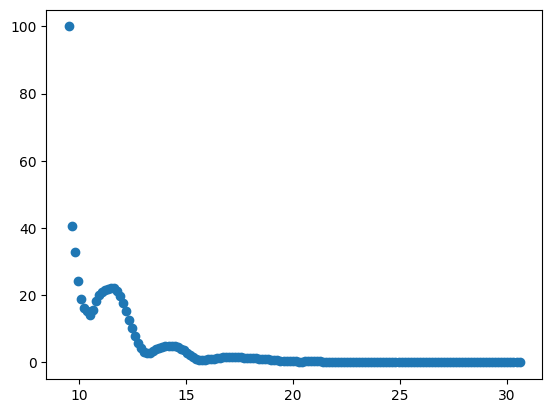

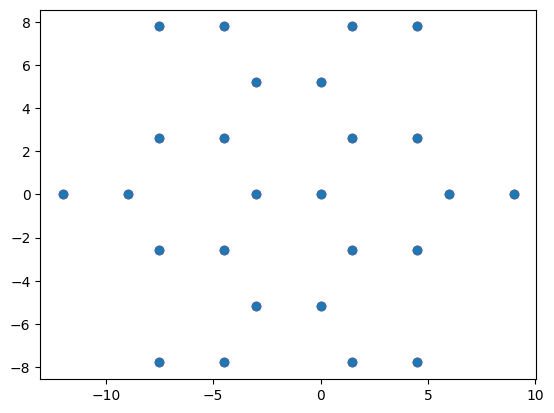

cc
Iteration 0: d-spacing = 9.5, Kept 676 distances
ec
Iteration 0: d-spacing = 9.5, Kept 616 distances
ce
Iteration 0: d-spacing = 9.5, Kept 616 distances
ee
Iteration 0: d-spacing = 9.5, Kept 494 distances


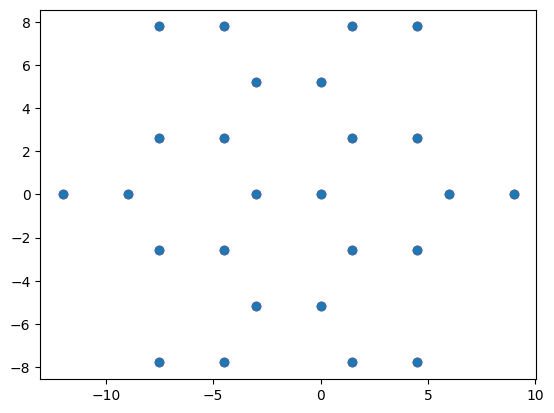

cc
Iteration 1: d-spacing = 9.641611, Kept 676 distances
ec
Iteration 1: d-spacing = 9.641611, Kept 616 distances
ce
Iteration 1: d-spacing = 9.641611, Kept 616 distances
ee
Iteration 1: d-spacing = 9.641611, Kept 494 distances


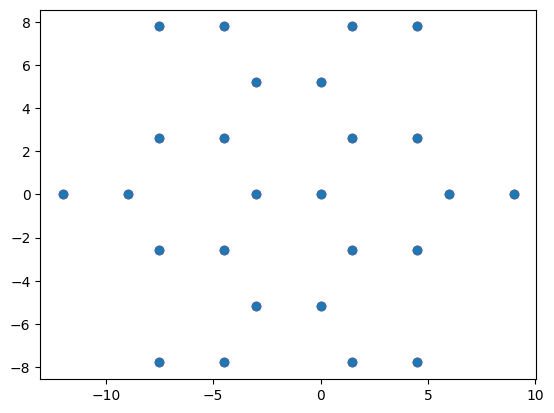

cc
Iteration 2: d-spacing = 9.783221, Kept 676 distances
ec
Iteration 2: d-spacing = 9.783221, Kept 616 distances
ce
Iteration 2: d-spacing = 9.783221, Kept 616 distances
ee
Iteration 2: d-spacing = 9.783221, Kept 494 distances


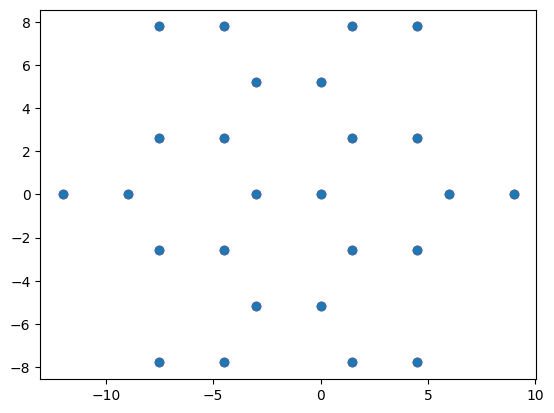

cc
Iteration 3: d-spacing = 9.924832, Kept 676 distances
ec
Iteration 3: d-spacing = 9.924832, Kept 616 distances
ce
Iteration 3: d-spacing = 9.924832, Kept 616 distances
ee
Iteration 3: d-spacing = 9.924832, Kept 494 distances


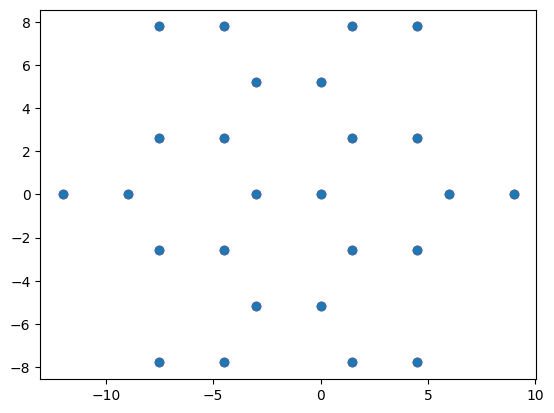

cc
Iteration 4: d-spacing = 10.066443, Kept 676 distances
ec
Iteration 4: d-spacing = 10.066443, Kept 616 distances
ce
Iteration 4: d-spacing = 10.066443, Kept 616 distances
ee
Iteration 4: d-spacing = 10.066443, Kept 494 distances


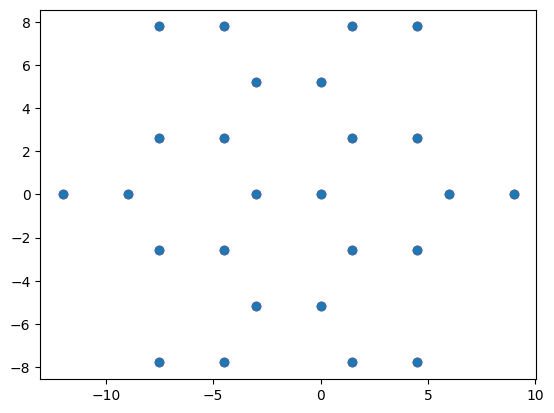

cc
Iteration 5: d-spacing = 10.208054, Kept 676 distances
ec
Iteration 5: d-spacing = 10.208054, Kept 616 distances
ce
Iteration 5: d-spacing = 10.208054, Kept 616 distances
ee
Iteration 5: d-spacing = 10.208054, Kept 494 distances


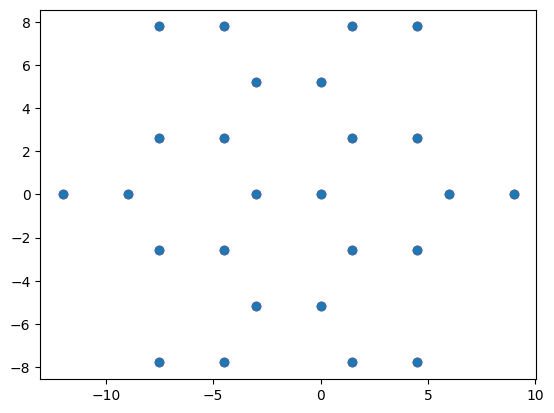

cc
Iteration 6: d-spacing = 10.349664, Kept 676 distances
ec
Iteration 6: d-spacing = 10.349664, Kept 616 distances
ce
Iteration 6: d-spacing = 10.349664, Kept 616 distances
ee
Iteration 6: d-spacing = 10.349664, Kept 494 distances


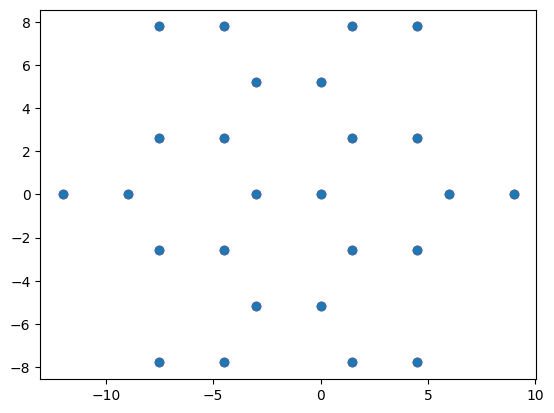

cc
Iteration 7: d-spacing = 10.491275, Kept 676 distances
ec
Iteration 7: d-spacing = 10.491275, Kept 616 distances
ce
Iteration 7: d-spacing = 10.491275, Kept 616 distances
ee
Iteration 7: d-spacing = 10.491275, Kept 494 distances


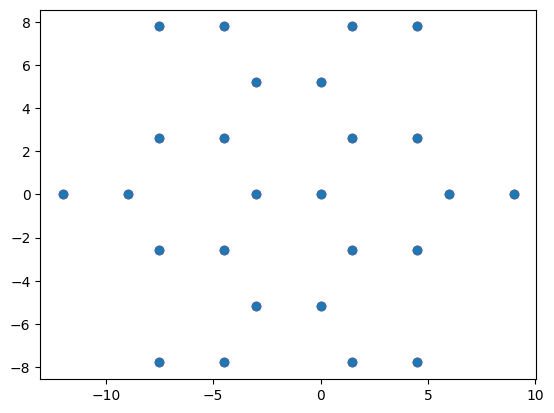

cc
Iteration 8: d-spacing = 10.632886, Kept 676 distances
ec
Iteration 8: d-spacing = 10.632886, Kept 612 distances
ce
Iteration 8: d-spacing = 10.632886, Kept 612 distances
ee
Iteration 8: d-spacing = 10.632886, Kept 486 distances


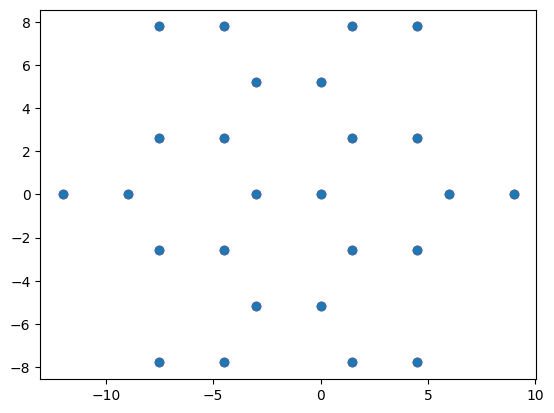

cc
Iteration 9: d-spacing = 10.774497, Kept 676 distances
ec
Iteration 9: d-spacing = 10.774497, Kept 612 distances
ce
Iteration 9: d-spacing = 10.774497, Kept 612 distances
ee
Iteration 9: d-spacing = 10.774497, Kept 482 distances


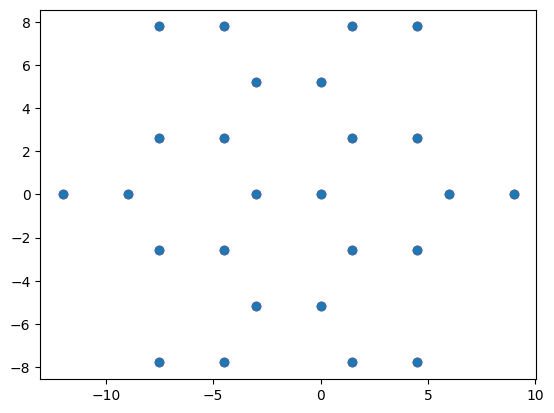

cc
Iteration 10: d-spacing = 10.916107, Kept 676 distances
ec
Iteration 10: d-spacing = 10.916107, Kept 612 distances
ce
Iteration 10: d-spacing = 10.916107, Kept 612 distances
ee
Iteration 10: d-spacing = 10.916107, Kept 482 distances


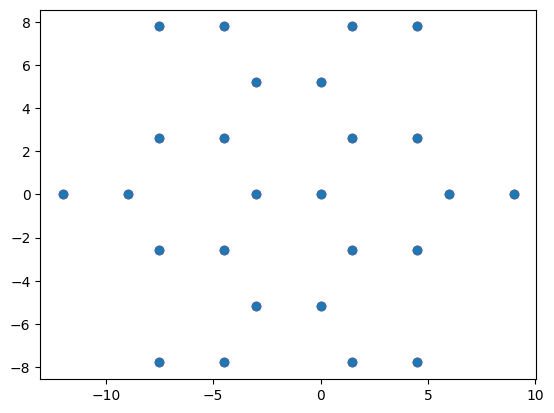

cc
Iteration 11: d-spacing = 11.057718, Kept 676 distances
ec
Iteration 11: d-spacing = 11.057718, Kept 612 distances
ce
Iteration 11: d-spacing = 11.057718, Kept 612 distances
ee
Iteration 11: d-spacing = 11.057718, Kept 482 distances


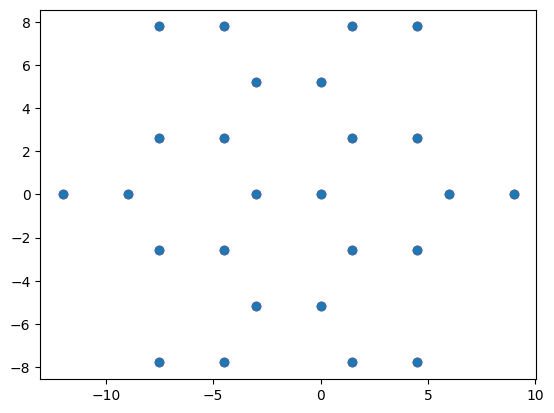

cc
Iteration 12: d-spacing = 11.199329, Kept 676 distances
ec
Iteration 12: d-spacing = 11.199329, Kept 600 distances
ce
Iteration 12: d-spacing = 11.199329, Kept 600 distances
ee
Iteration 12: d-spacing = 11.199329, Kept 482 distances


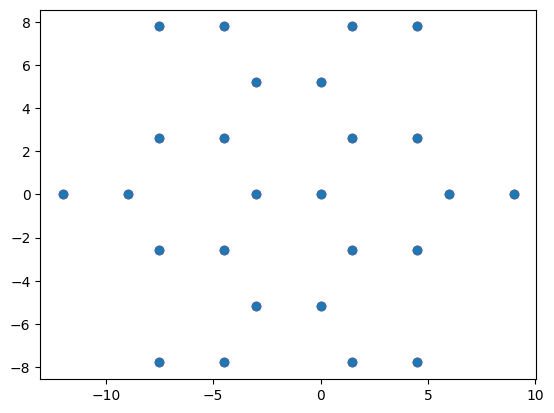

cc
Iteration 13: d-spacing = 11.34094, Kept 676 distances
ec
Iteration 13: d-spacing = 11.34094, Kept 600 distances
ce
Iteration 13: d-spacing = 11.34094, Kept 600 distances
ee
Iteration 13: d-spacing = 11.34094, Kept 482 distances


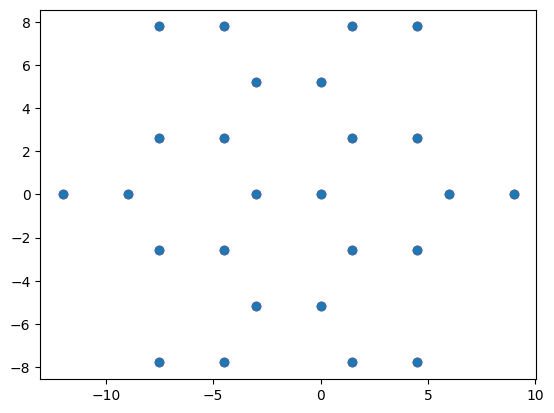

cc
Iteration 14: d-spacing = 11.48255, Kept 676 distances
ec
Iteration 14: d-spacing = 11.48255, Kept 600 distances
ce
Iteration 14: d-spacing = 11.48255, Kept 600 distances
ee
Iteration 14: d-spacing = 11.48255, Kept 482 distances


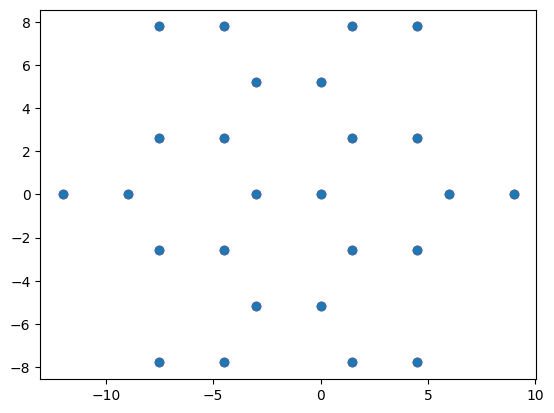

cc
Iteration 15: d-spacing = 11.624161, Kept 676 distances
ec
Iteration 15: d-spacing = 11.624161, Kept 600 distances
ce
Iteration 15: d-spacing = 11.624161, Kept 600 distances
ee
Iteration 15: d-spacing = 11.624161, Kept 482 distances


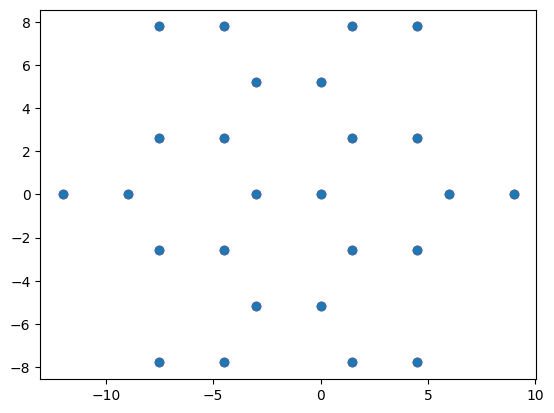

cc
Iteration 16: d-spacing = 11.765772, Kept 676 distances
ec
Iteration 16: d-spacing = 11.765772, Kept 588 distances
ce
Iteration 16: d-spacing = 11.765772, Kept 588 distances
ee
Iteration 16: d-spacing = 11.765772, Kept 482 distances


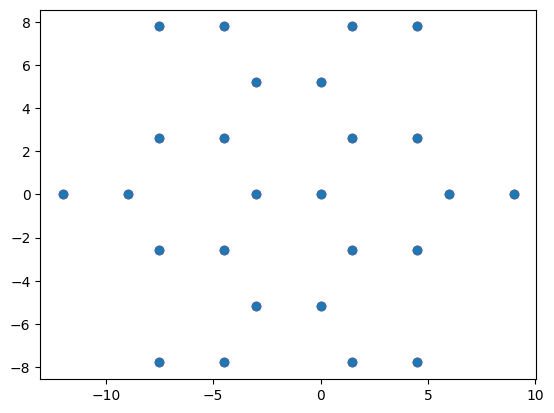

cc
Iteration 17: d-spacing = 11.907383, Kept 676 distances
ec
Iteration 17: d-spacing = 11.907383, Kept 588 distances
ce
Iteration 17: d-spacing = 11.907383, Kept 588 distances
ee
Iteration 17: d-spacing = 11.907383, Kept 482 distances


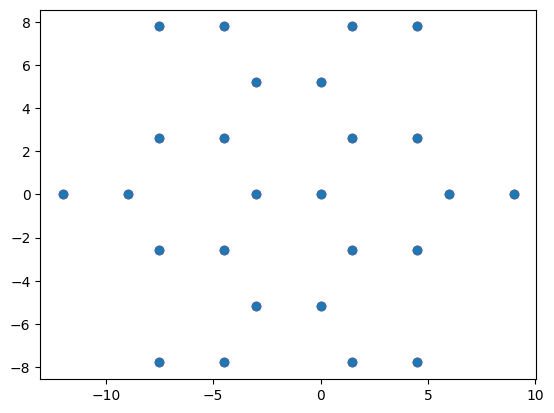

cc
Iteration 18: d-spacing = 12.048993, Kept 670 distances
ec
Iteration 18: d-spacing = 12.048993, Kept 588 distances
ce
Iteration 18: d-spacing = 12.048993, Kept 588 distances
ee
Iteration 18: d-spacing = 12.048993, Kept 470 distances


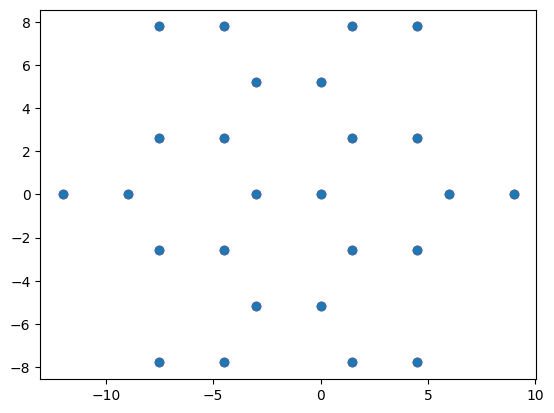

cc
Iteration 19: d-spacing = 12.190604, Kept 670 distances
ec
Iteration 19: d-spacing = 12.190604, Kept 588 distances
ce
Iteration 19: d-spacing = 12.190604, Kept 588 distances
ee
Iteration 19: d-spacing = 12.190604, Kept 470 distances


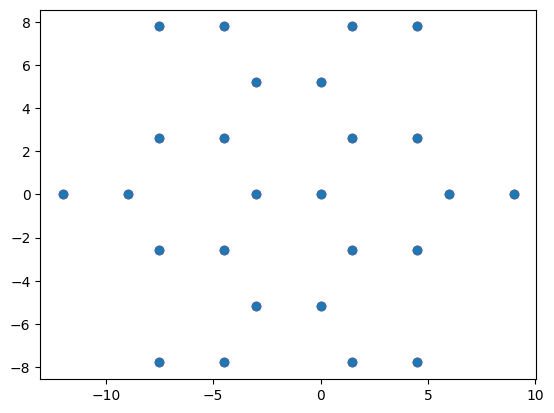

cc
Iteration 20: d-spacing = 12.332215, Kept 670 distances
ec
Iteration 20: d-spacing = 12.332215, Kept 588 distances
ce
Iteration 20: d-spacing = 12.332215, Kept 588 distances
ee
Iteration 20: d-spacing = 12.332215, Kept 470 distances


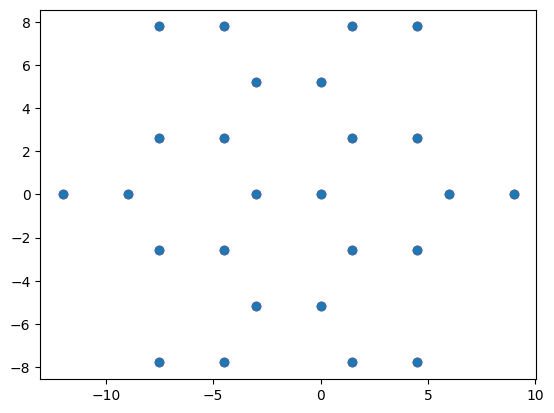

cc
Iteration 21: d-spacing = 12.473826, Kept 670 distances
ec
Iteration 21: d-spacing = 12.473826, Kept 588 distances
ce
Iteration 21: d-spacing = 12.473826, Kept 588 distances
ee
Iteration 21: d-spacing = 12.473826, Kept 470 distances


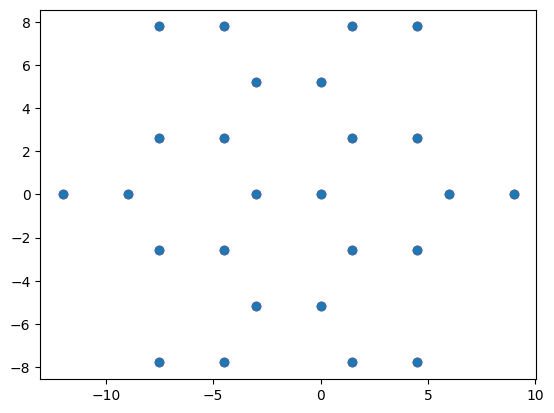

cc
Iteration 22: d-spacing = 12.615436, Kept 670 distances
ec
Iteration 22: d-spacing = 12.615436, Kept 584 distances
ce
Iteration 22: d-spacing = 12.615436, Kept 584 distances
ee
Iteration 22: d-spacing = 12.615436, Kept 464 distances


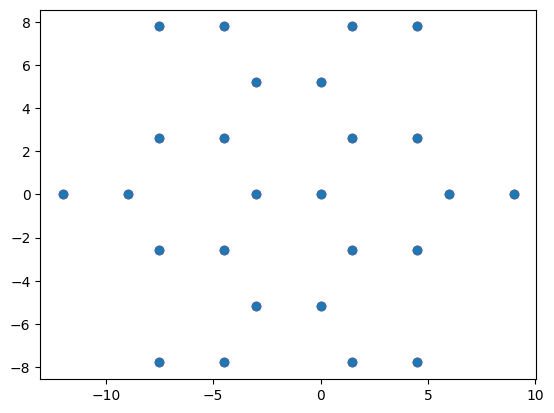

cc
Iteration 23: d-spacing = 12.757047, Kept 670 distances
ec
Iteration 23: d-spacing = 12.757047, Kept 584 distances
ce
Iteration 23: d-spacing = 12.757047, Kept 584 distances
ee
Iteration 23: d-spacing = 12.757047, Kept 464 distances


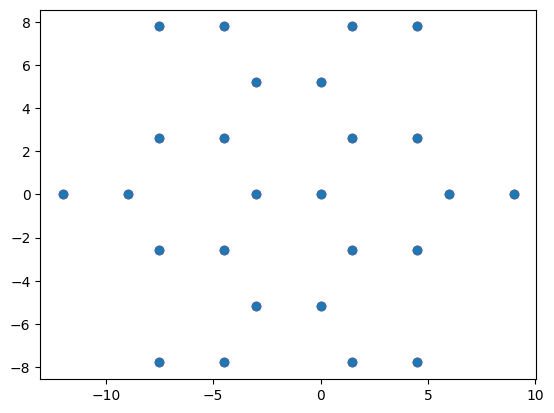

cc
Iteration 24: d-spacing = 12.898658, Kept 670 distances
ec
Iteration 24: d-spacing = 12.898658, Kept 584 distances
ce
Iteration 24: d-spacing = 12.898658, Kept 584 distances
ee
Iteration 24: d-spacing = 12.898658, Kept 464 distances


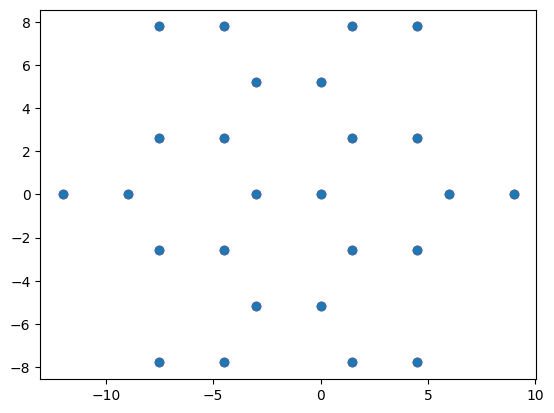

cc
Iteration 25: d-spacing = 13.040268, Kept 670 distances
ec
Iteration 25: d-spacing = 13.040268, Kept 584 distances
ce
Iteration 25: d-spacing = 13.040268, Kept 584 distances
ee
Iteration 25: d-spacing = 13.040268, Kept 464 distances


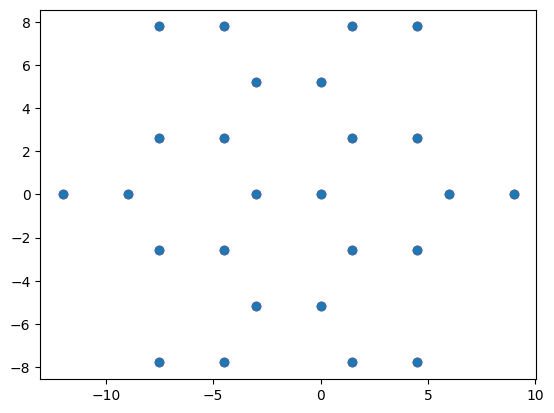

cc
Iteration 26: d-spacing = 13.181879, Kept 670 distances
ec
Iteration 26: d-spacing = 13.181879, Kept 572 distances
ce
Iteration 26: d-spacing = 13.181879, Kept 572 distances
ee
Iteration 26: d-spacing = 13.181879, Kept 464 distances


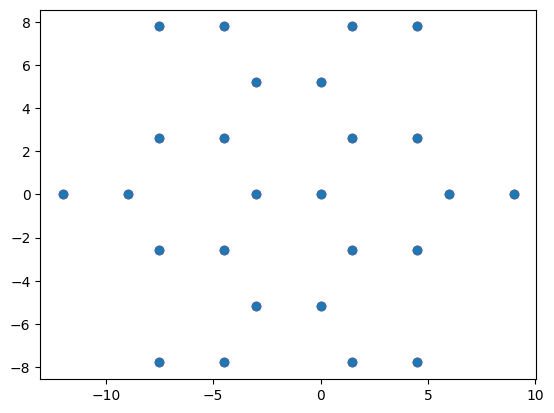

cc
Iteration 27: d-spacing = 13.32349, Kept 670 distances
ec
Iteration 27: d-spacing = 13.32349, Kept 572 distances
ce
Iteration 27: d-spacing = 13.32349, Kept 572 distances
ee
Iteration 27: d-spacing = 13.32349, Kept 464 distances


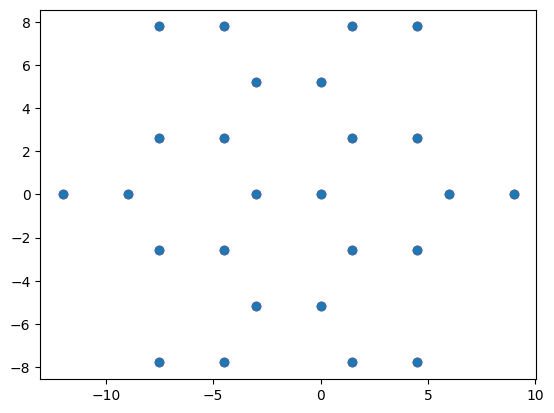

cc
Iteration 28: d-spacing = 13.465101, Kept 670 distances
ec
Iteration 28: d-spacing = 13.465101, Kept 572 distances
ce
Iteration 28: d-spacing = 13.465101, Kept 572 distances
ee
Iteration 28: d-spacing = 13.465101, Kept 464 distances


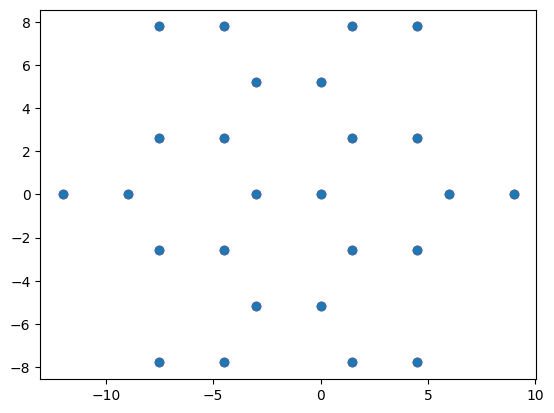

cc
Iteration 29: d-spacing = 13.606711, Kept 668 distances
ec
Iteration 29: d-spacing = 13.606711, Kept 564 distances
ce
Iteration 29: d-spacing = 13.606711, Kept 564 distances
ee
Iteration 29: d-spacing = 13.606711, Kept 448 distances


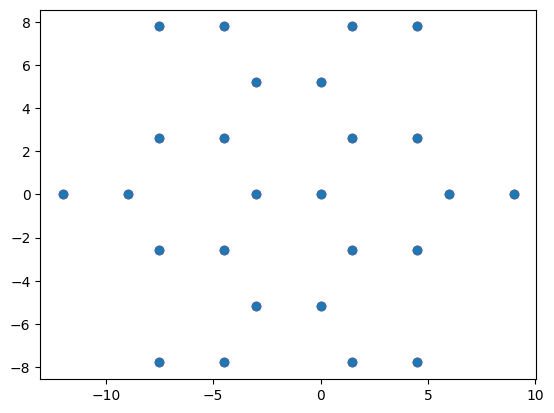

cc
Iteration 30: d-spacing = 13.748322, Kept 668 distances
ec
Iteration 30: d-spacing = 13.748322, Kept 564 distances
ce
Iteration 30: d-spacing = 13.748322, Kept 564 distances
ee
Iteration 30: d-spacing = 13.748322, Kept 438 distances


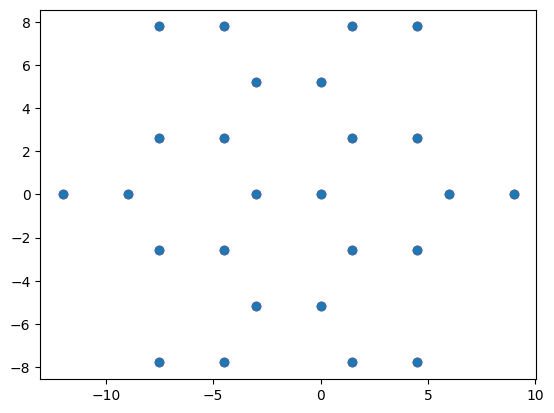

cc
Iteration 31: d-spacing = 13.889933, Kept 668 distances
ec
Iteration 31: d-spacing = 13.889933, Kept 564 distances
ce
Iteration 31: d-spacing = 13.889933, Kept 564 distances
ee
Iteration 31: d-spacing = 13.889933, Kept 414 distances


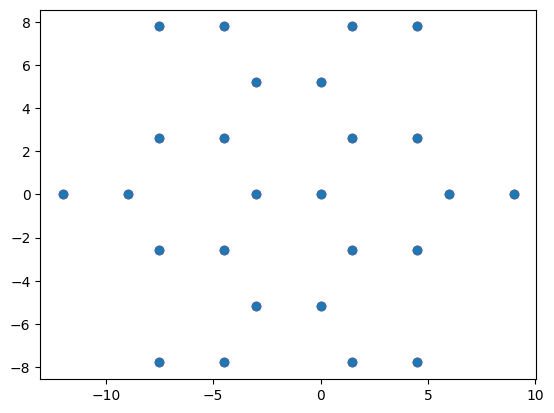

cc
Iteration 32: d-spacing = 14.031544, Kept 668 distances
ec
Iteration 32: d-spacing = 14.031544, Kept 560 distances
ce
Iteration 32: d-spacing = 14.031544, Kept 560 distances
ee
Iteration 32: d-spacing = 14.031544, Kept 414 distances


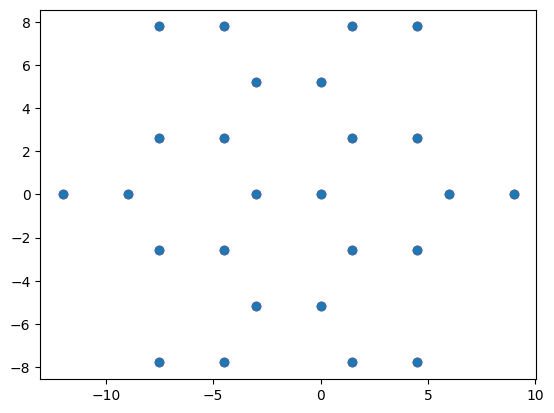

cc
Iteration 33: d-spacing = 14.173154, Kept 656 distances
ec
Iteration 33: d-spacing = 14.173154, Kept 554 distances
ce
Iteration 33: d-spacing = 14.173154, Kept 554 distances
ee
Iteration 33: d-spacing = 14.173154, Kept 414 distances


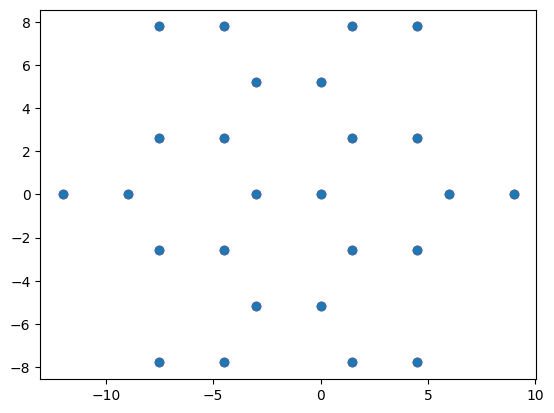

cc
Iteration 34: d-spacing = 14.314765, Kept 656 distances
ec
Iteration 34: d-spacing = 14.314765, Kept 554 distances
ce
Iteration 34: d-spacing = 14.314765, Kept 554 distances
ee
Iteration 34: d-spacing = 14.314765, Kept 414 distances


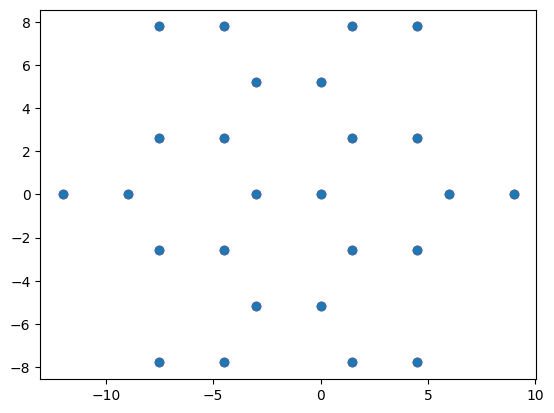

cc
Iteration 35: d-spacing = 14.456376, Kept 656 distances
ec
Iteration 35: d-spacing = 14.456376, Kept 554 distances
ce
Iteration 35: d-spacing = 14.456376, Kept 554 distances
ee
Iteration 35: d-spacing = 14.456376, Kept 414 distances


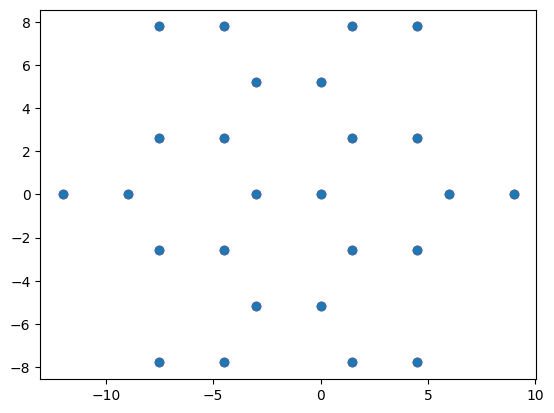

cc
Iteration 36: d-spacing = 14.597987, Kept 656 distances
ec
Iteration 36: d-spacing = 14.597987, Kept 554 distances
ce
Iteration 36: d-spacing = 14.597987, Kept 554 distances
ee
Iteration 36: d-spacing = 14.597987, Kept 414 distances


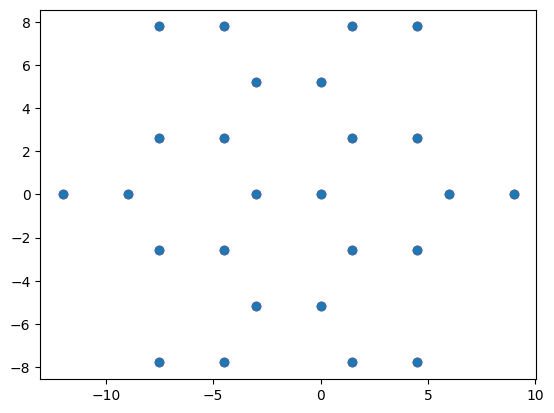

cc
Iteration 37: d-spacing = 14.739597, Kept 656 distances
ec
Iteration 37: d-spacing = 14.739597, Kept 554 distances
ce
Iteration 37: d-spacing = 14.739597, Kept 554 distances
ee
Iteration 37: d-spacing = 14.739597, Kept 414 distances


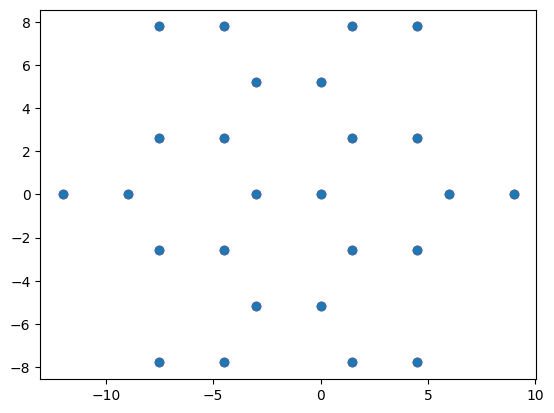

cc
Iteration 38: d-spacing = 14.881208, Kept 656 distances
ec
Iteration 38: d-spacing = 14.881208, Kept 554 distances
ce
Iteration 38: d-spacing = 14.881208, Kept 554 distances
ee
Iteration 38: d-spacing = 14.881208, Kept 414 distances


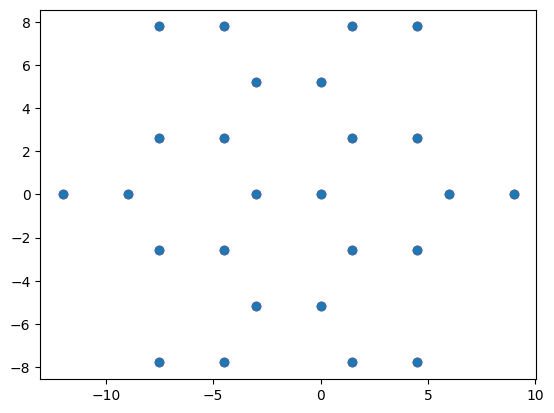

cc
Iteration 39: d-spacing = 15.022819, Kept 656 distances
ec
Iteration 39: d-spacing = 15.022819, Kept 554 distances
ce
Iteration 39: d-spacing = 15.022819, Kept 554 distances
ee
Iteration 39: d-spacing = 15.022819, Kept 414 distances


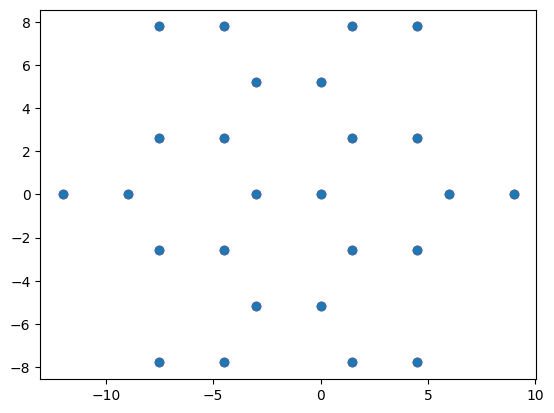

cc
Iteration 40: d-spacing = 15.16443, Kept 656 distances
ec
Iteration 40: d-spacing = 15.16443, Kept 554 distances
ce
Iteration 40: d-spacing = 15.16443, Kept 554 distances
ee
Iteration 40: d-spacing = 15.16443, Kept 414 distances


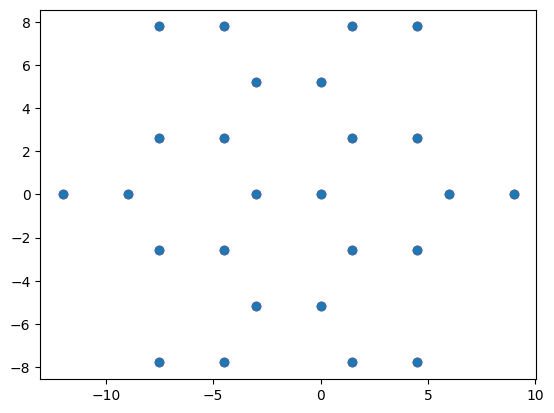

cc
Iteration 41: d-spacing = 15.30604, Kept 656 distances
ec
Iteration 41: d-spacing = 15.30604, Kept 554 distances
ce
Iteration 41: d-spacing = 15.30604, Kept 554 distances
ee
Iteration 41: d-spacing = 15.30604, Kept 414 distances


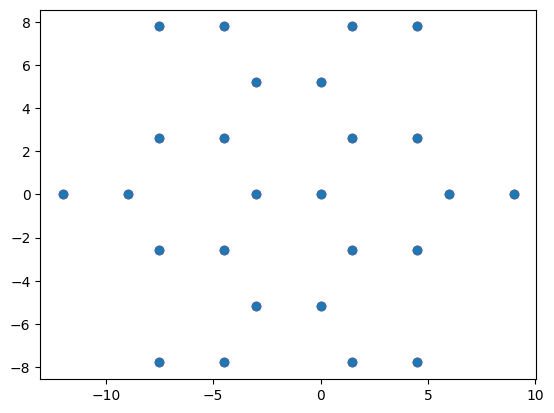

cc
Iteration 42: d-spacing = 15.447651, Kept 652 distances
ec
Iteration 42: d-spacing = 15.447651, Kept 550 distances
ce
Iteration 42: d-spacing = 15.447651, Kept 550 distances
ee
Iteration 42: d-spacing = 15.447651, Kept 406 distances


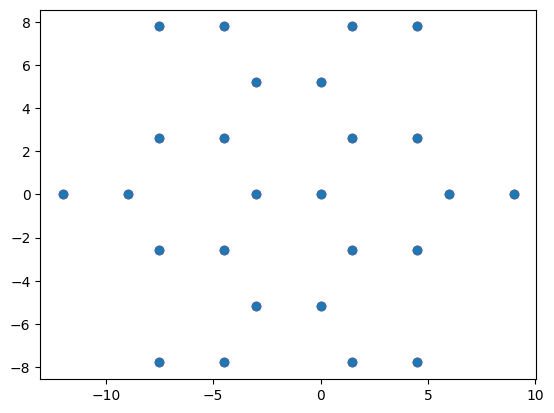

cc
Iteration 43: d-spacing = 15.589262, Kept 628 distances
ec
Iteration 43: d-spacing = 15.589262, Kept 518 distances
ce
Iteration 43: d-spacing = 15.589262, Kept 518 distances
ee
Iteration 43: d-spacing = 15.589262, Kept 398 distances


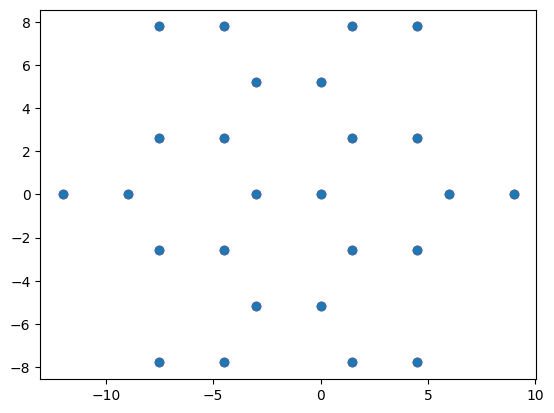

cc
Iteration 44: d-spacing = 15.730872, Kept 628 distances
ec
Iteration 44: d-spacing = 15.730872, Kept 518 distances
ce
Iteration 44: d-spacing = 15.730872, Kept 518 distances
ee
Iteration 44: d-spacing = 15.730872, Kept 398 distances


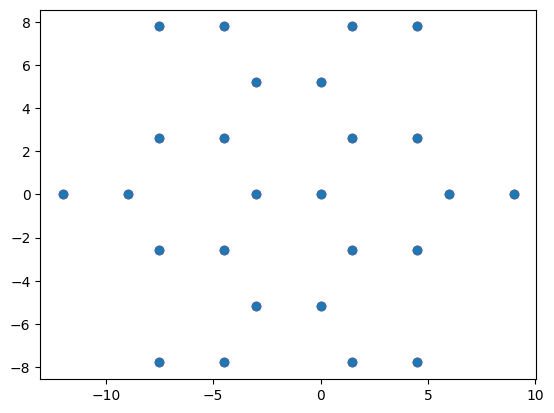

cc
Iteration 45: d-spacing = 15.872483, Kept 628 distances
ec
Iteration 45: d-spacing = 15.872483, Kept 518 distances
ce
Iteration 45: d-spacing = 15.872483, Kept 518 distances
ee
Iteration 45: d-spacing = 15.872483, Kept 398 distances


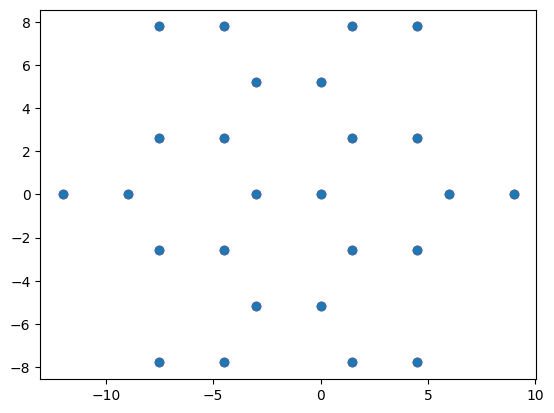

cc
Iteration 46: d-spacing = 16.014094, Kept 628 distances
ec
Iteration 46: d-spacing = 16.014094, Kept 506 distances
ce
Iteration 46: d-spacing = 16.014094, Kept 506 distances
ee
Iteration 46: d-spacing = 16.014094, Kept 398 distances


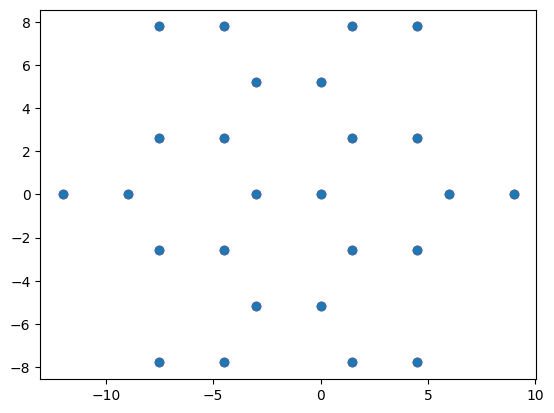

cc
Iteration 47: d-spacing = 16.155705, Kept 628 distances
ec
Iteration 47: d-spacing = 16.155705, Kept 506 distances
ce
Iteration 47: d-spacing = 16.155705, Kept 506 distances
ee
Iteration 47: d-spacing = 16.155705, Kept 398 distances


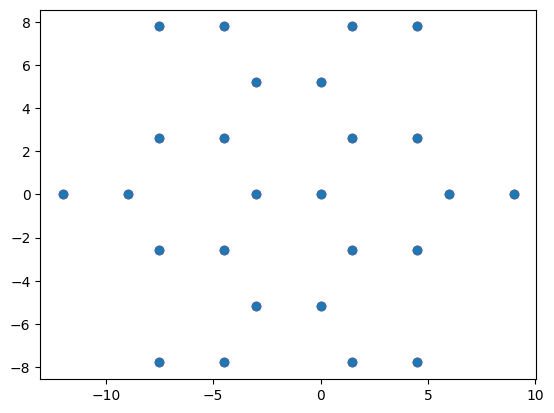

cc
Iteration 48: d-spacing = 16.297315, Kept 628 distances
ec
Iteration 48: d-spacing = 16.297315, Kept 506 distances
ce
Iteration 48: d-spacing = 16.297315, Kept 506 distances
ee
Iteration 48: d-spacing = 16.297315, Kept 398 distances


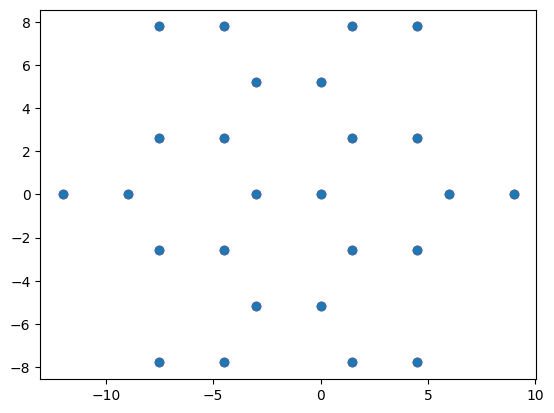

cc
Iteration 49: d-spacing = 16.438926, Kept 628 distances
ec
Iteration 49: d-spacing = 16.438926, Kept 506 distances
ce
Iteration 49: d-spacing = 16.438926, Kept 506 distances
ee
Iteration 49: d-spacing = 16.438926, Kept 398 distances


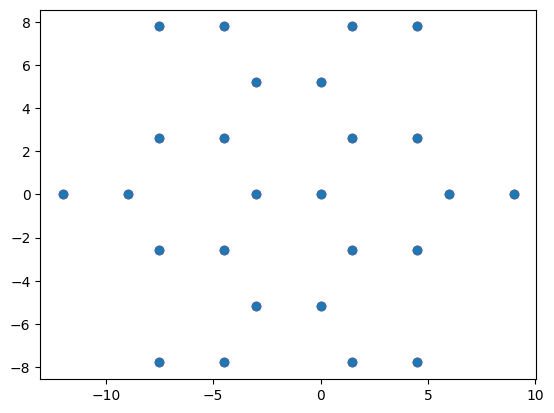

cc
Iteration 50: d-spacing = 16.580537, Kept 628 distances
ec
Iteration 50: d-spacing = 16.580537, Kept 492 distances
ce
Iteration 50: d-spacing = 16.580537, Kept 492 distances
ee
Iteration 50: d-spacing = 16.580537, Kept 378 distances


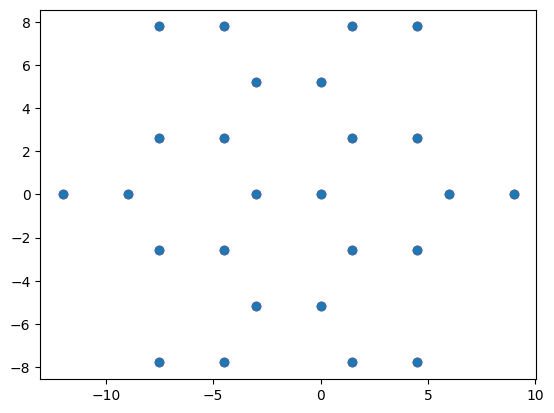

cc
Iteration 51: d-spacing = 16.722148, Kept 628 distances
ec
Iteration 51: d-spacing = 16.722148, Kept 492 distances
ce
Iteration 51: d-spacing = 16.722148, Kept 492 distances
ee
Iteration 51: d-spacing = 16.722148, Kept 370 distances


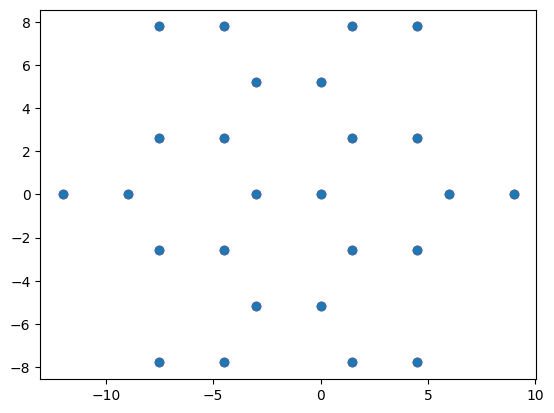

cc
Iteration 52: d-spacing = 16.863758, Kept 628 distances
ec
Iteration 52: d-spacing = 16.863758, Kept 492 distances
ce
Iteration 52: d-spacing = 16.863758, Kept 492 distances
ee
Iteration 52: d-spacing = 16.863758, Kept 370 distances


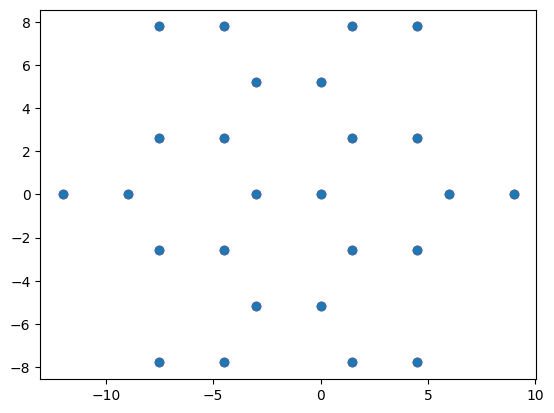

cc
Iteration 53: d-spacing = 17.005369, Kept 628 distances
ec
Iteration 53: d-spacing = 17.005369, Kept 492 distances
ce
Iteration 53: d-spacing = 17.005369, Kept 492 distances
ee
Iteration 53: d-spacing = 17.005369, Kept 370 distances


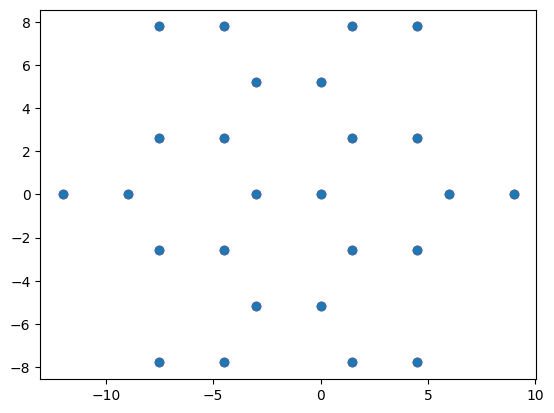

cc
Iteration 54: d-spacing = 17.14698, Kept 620 distances
ec
Iteration 54: d-spacing = 17.14698, Kept 468 distances
ce
Iteration 54: d-spacing = 17.14698, Kept 468 distances
ee
Iteration 54: d-spacing = 17.14698, Kept 350 distances


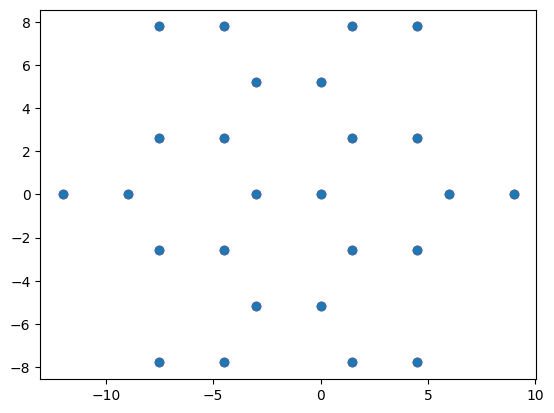

cc
Iteration 55: d-spacing = 17.288591, Kept 620 distances
ec
Iteration 55: d-spacing = 17.288591, Kept 468 distances
ce
Iteration 55: d-spacing = 17.288591, Kept 468 distances
ee
Iteration 55: d-spacing = 17.288591, Kept 350 distances


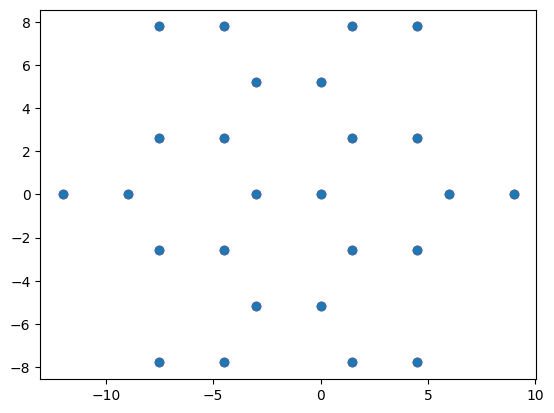

cc
Iteration 56: d-spacing = 17.430201, Kept 590 distances
ec
Iteration 56: d-spacing = 17.430201, Kept 456 distances
ce
Iteration 56: d-spacing = 17.430201, Kept 456 distances
ee
Iteration 56: d-spacing = 17.430201, Kept 338 distances


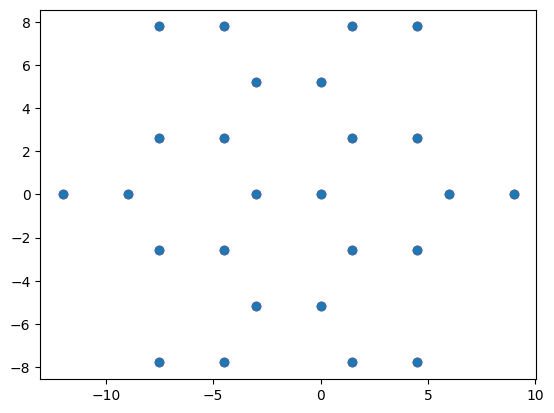

cc
Iteration 57: d-spacing = 17.571812, Kept 590 distances
ec
Iteration 57: d-spacing = 17.571812, Kept 456 distances
ce
Iteration 57: d-spacing = 17.571812, Kept 456 distances
ee
Iteration 57: d-spacing = 17.571812, Kept 338 distances


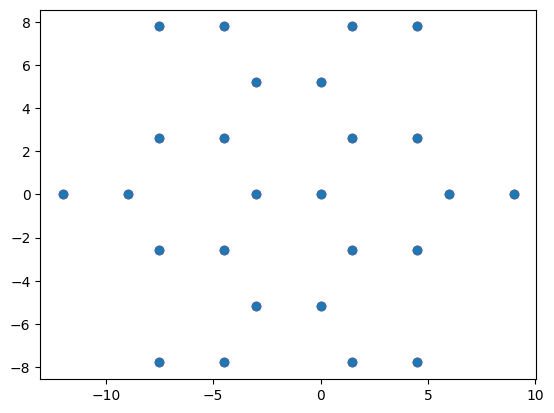

cc
Iteration 58: d-spacing = 17.713423, Kept 590 distances
ec
Iteration 58: d-spacing = 17.713423, Kept 456 distances
ce
Iteration 58: d-spacing = 17.713423, Kept 456 distances
ee
Iteration 58: d-spacing = 17.713423, Kept 338 distances


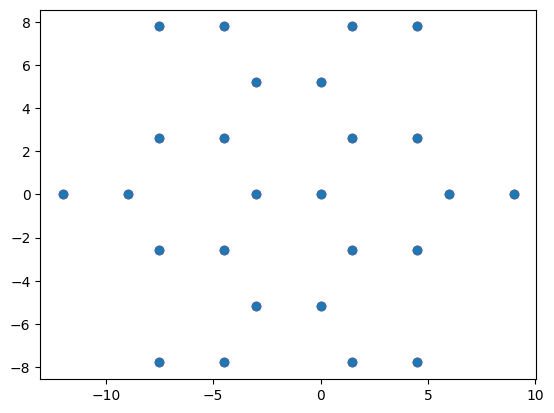

cc
Iteration 59: d-spacing = 17.855034, Kept 590 distances
ec
Iteration 59: d-spacing = 17.855034, Kept 456 distances
ce
Iteration 59: d-spacing = 17.855034, Kept 456 distances
ee
Iteration 59: d-spacing = 17.855034, Kept 338 distances


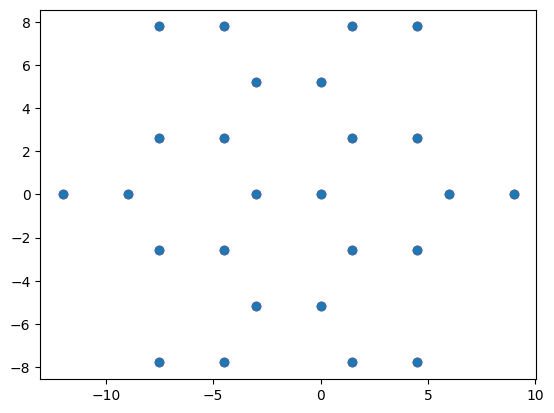

cc
Iteration 60: d-spacing = 17.996644, Kept 554 distances
ec
Iteration 60: d-spacing = 17.996644, Kept 444 distances
ce
Iteration 60: d-spacing = 17.996644, Kept 444 distances
ee
Iteration 60: d-spacing = 17.996644, Kept 338 distances


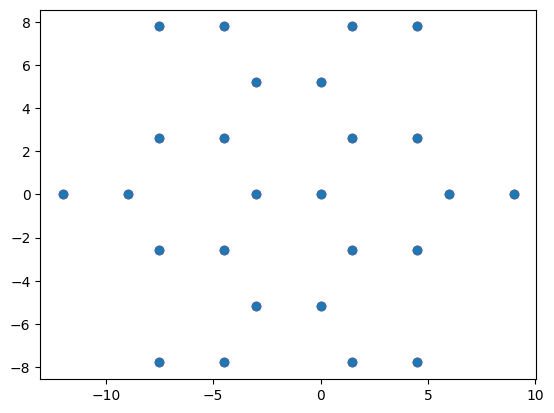

cc
Iteration 61: d-spacing = 18.138255, Kept 554 distances
ec
Iteration 61: d-spacing = 18.138255, Kept 444 distances
ce
Iteration 61: d-spacing = 18.138255, Kept 444 distances
ee
Iteration 61: d-spacing = 18.138255, Kept 314 distances


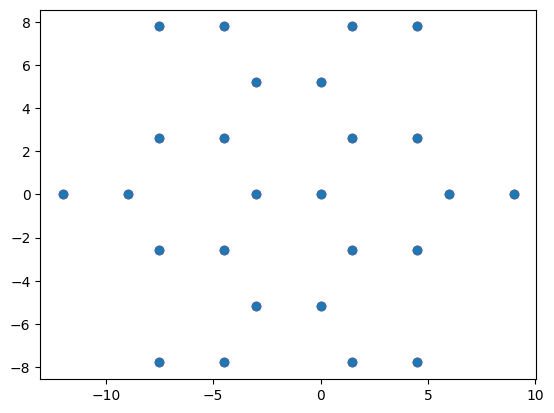

cc
Iteration 62: d-spacing = 18.279866, Kept 554 distances
ec
Iteration 62: d-spacing = 18.279866, Kept 432 distances
ce
Iteration 62: d-spacing = 18.279866, Kept 432 distances
ee
Iteration 62: d-spacing = 18.279866, Kept 314 distances


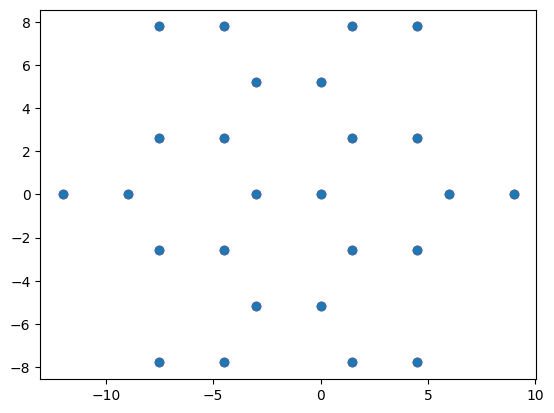

cc
Iteration 63: d-spacing = 18.421477, Kept 554 distances
ec
Iteration 63: d-spacing = 18.421477, Kept 432 distances
ce
Iteration 63: d-spacing = 18.421477, Kept 432 distances
ee
Iteration 63: d-spacing = 18.421477, Kept 314 distances


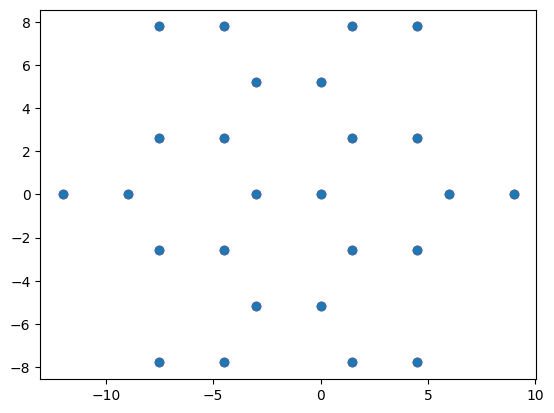

cc
Iteration 64: d-spacing = 18.563087, Kept 554 distances
ec
Iteration 64: d-spacing = 18.563087, Kept 432 distances
ce
Iteration 64: d-spacing = 18.563087, Kept 432 distances
ee
Iteration 64: d-spacing = 18.563087, Kept 314 distances


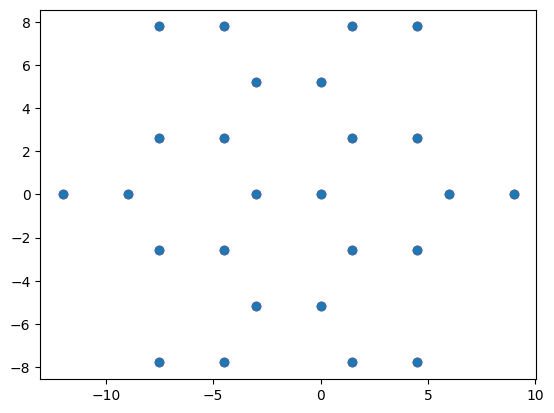

cc
Iteration 65: d-spacing = 18.704698, Kept 542 distances
ec
Iteration 65: d-spacing = 18.704698, Kept 420 distances
ce
Iteration 65: d-spacing = 18.704698, Kept 420 distances
ee
Iteration 65: d-spacing = 18.704698, Kept 298 distances


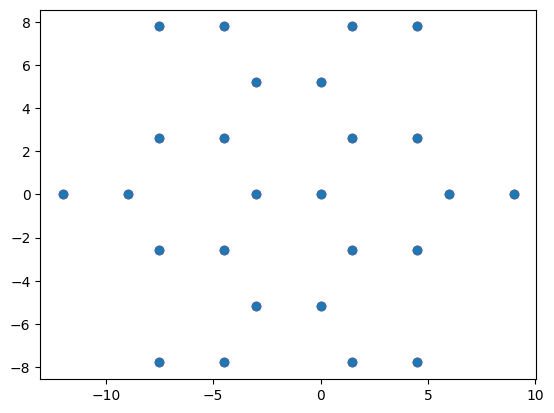

cc
Iteration 66: d-spacing = 18.846309, Kept 542 distances
ec
Iteration 66: d-spacing = 18.846309, Kept 420 distances
ce
Iteration 66: d-spacing = 18.846309, Kept 420 distances
ee
Iteration 66: d-spacing = 18.846309, Kept 274 distances


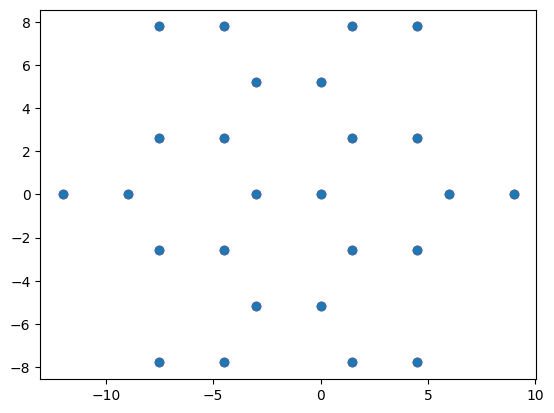

cc
Iteration 67: d-spacing = 18.987919, Kept 542 distances
ec
Iteration 67: d-spacing = 18.987919, Kept 420 distances
ce
Iteration 67: d-spacing = 18.987919, Kept 420 distances
ee
Iteration 67: d-spacing = 18.987919, Kept 274 distances


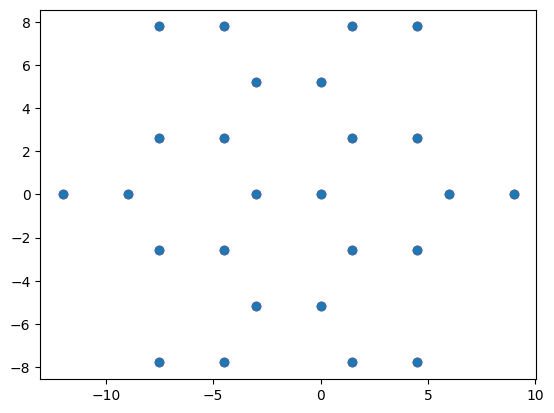

cc
Iteration 68: d-spacing = 19.12953, Kept 494 distances
ec
Iteration 68: d-spacing = 19.12953, Kept 396 distances
ce
Iteration 68: d-spacing = 19.12953, Kept 396 distances
ee
Iteration 68: d-spacing = 19.12953, Kept 274 distances


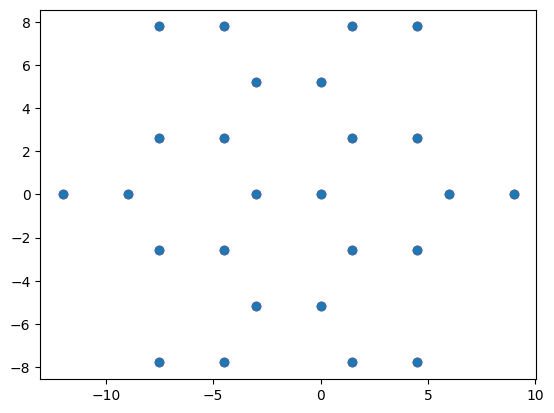

cc
Iteration 69: d-spacing = 19.271141, Kept 494 distances
ec
Iteration 69: d-spacing = 19.271141, Kept 396 distances
ce
Iteration 69: d-spacing = 19.271141, Kept 396 distances
ee
Iteration 69: d-spacing = 19.271141, Kept 274 distances


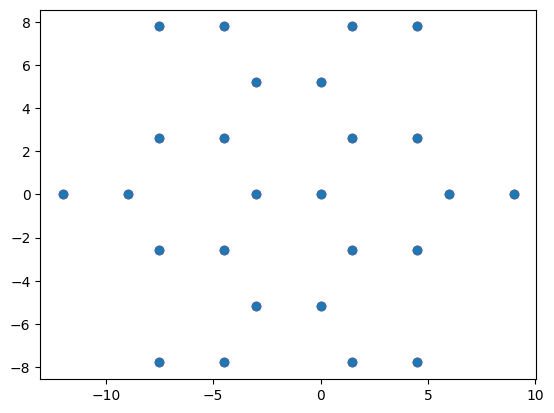

cc
Iteration 70: d-spacing = 19.412752, Kept 478 distances
ec
Iteration 70: d-spacing = 19.412752, Kept 362 distances
ce
Iteration 70: d-spacing = 19.412752, Kept 362 distances
ee
Iteration 70: d-spacing = 19.412752, Kept 256 distances


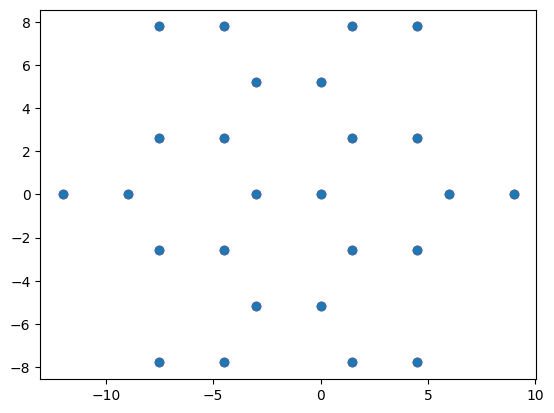

cc
Iteration 71: d-spacing = 19.554362, Kept 478 distances
ec
Iteration 71: d-spacing = 19.554362, Kept 358 distances
ce
Iteration 71: d-spacing = 19.554362, Kept 358 distances
ee
Iteration 71: d-spacing = 19.554362, Kept 256 distances


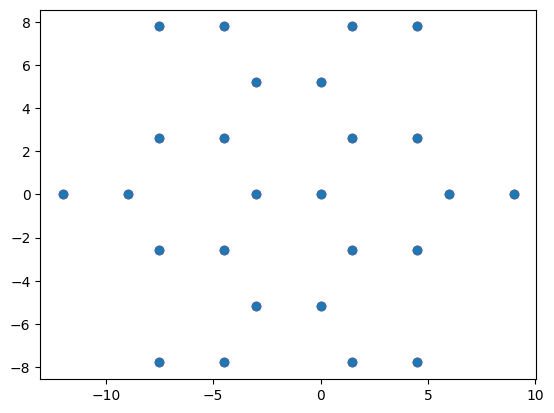

cc
Iteration 72: d-spacing = 19.695973, Kept 465 distances
ec
Iteration 72: d-spacing = 19.695973, Kept 354 distances
ce
Iteration 72: d-spacing = 19.695973, Kept 354 distances
ee
Iteration 72: d-spacing = 19.695973, Kept 236 distances


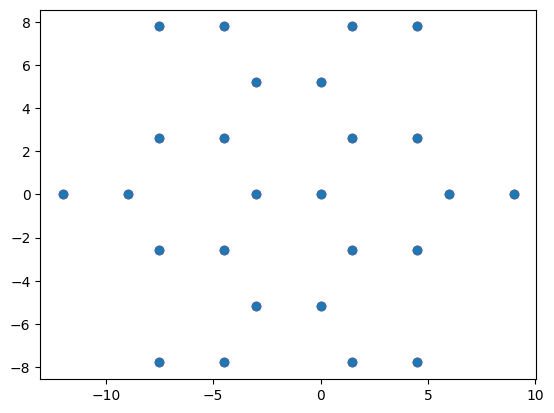

cc
Iteration 73: d-spacing = 19.837584, Kept 465 distances
ec
Iteration 73: d-spacing = 19.837584, Kept 354 distances
ce
Iteration 73: d-spacing = 19.837584, Kept 354 distances
ee
Iteration 73: d-spacing = 19.837584, Kept 236 distances


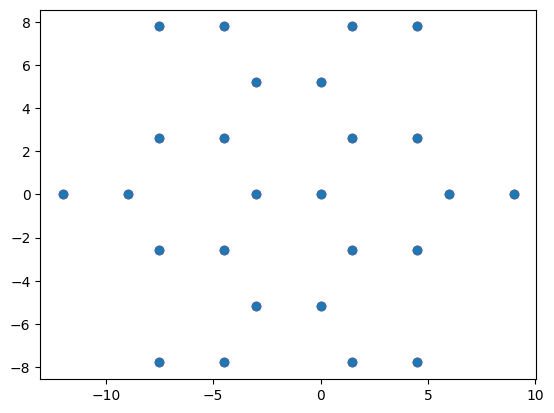

cc
Iteration 74: d-spacing = 19.979195, Kept 465 distances
ec
Iteration 74: d-spacing = 19.979195, Kept 354 distances
ce
Iteration 74: d-spacing = 19.979195, Kept 354 distances
ee
Iteration 74: d-spacing = 19.979195, Kept 236 distances


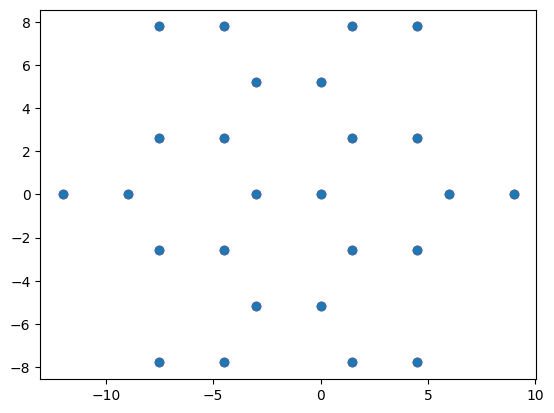

cc
Iteration 75: d-spacing = 20.120805, Kept 455 distances
ec
Iteration 75: d-spacing = 20.120805, Kept 340 distances
ce
Iteration 75: d-spacing = 20.120805, Kept 340 distances
ee
Iteration 75: d-spacing = 20.120805, Kept 228 distances


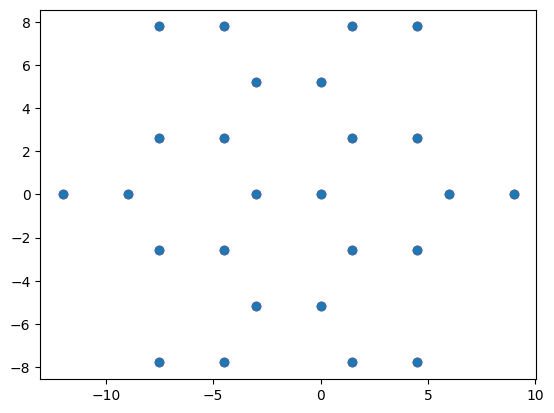

cc
Iteration 76: d-spacing = 20.262416, Kept 455 distances
ec
Iteration 76: d-spacing = 20.262416, Kept 340 distances
ce
Iteration 76: d-spacing = 20.262416, Kept 340 distances
ee
Iteration 76: d-spacing = 20.262416, Kept 228 distances


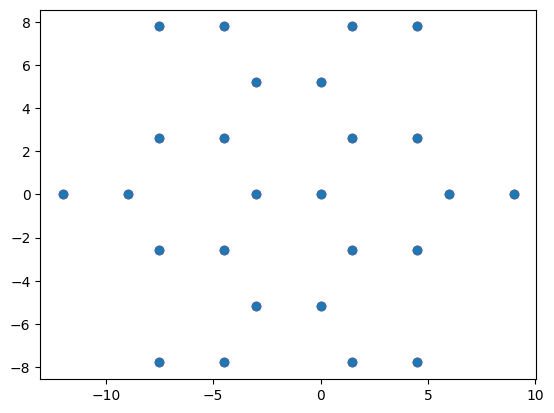

cc
Iteration 77: d-spacing = 20.404027, Kept 455 distances
ec
Iteration 77: d-spacing = 20.404027, Kept 340 distances
ce
Iteration 77: d-spacing = 20.404027, Kept 340 distances
ee
Iteration 77: d-spacing = 20.404027, Kept 228 distances


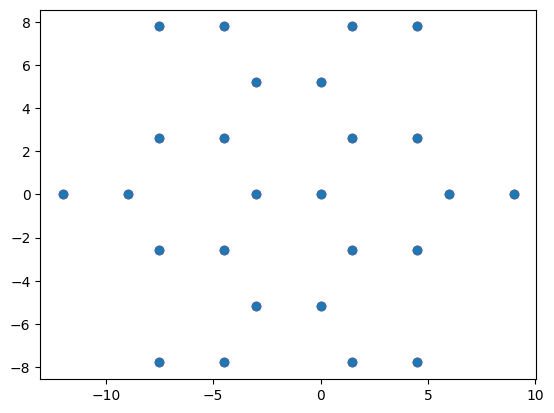

cc
Iteration 78: d-spacing = 20.545638, Kept 455 distances
ec
Iteration 78: d-spacing = 20.545638, Kept 340 distances
ce
Iteration 78: d-spacing = 20.545638, Kept 340 distances
ee
Iteration 78: d-spacing = 20.545638, Kept 228 distances


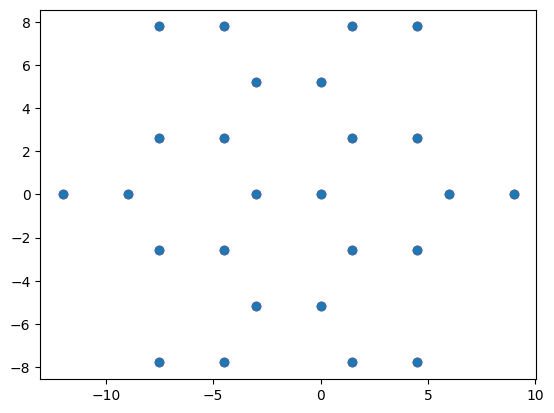

cc
Iteration 79: d-spacing = 20.687248, Kept 455 distances
ec
Iteration 79: d-spacing = 20.687248, Kept 340 distances
ce
Iteration 79: d-spacing = 20.687248, Kept 340 distances
ee
Iteration 79: d-spacing = 20.687248, Kept 228 distances


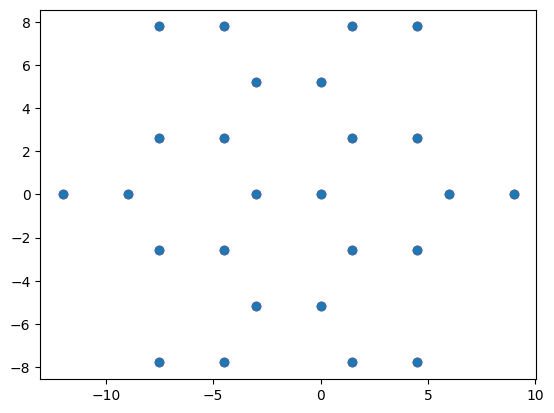

cc
Iteration 80: d-spacing = 20.828859, Kept 455 distances
ec
Iteration 80: d-spacing = 20.828859, Kept 340 distances
ce
Iteration 80: d-spacing = 20.828859, Kept 340 distances
ee
Iteration 80: d-spacing = 20.828859, Kept 228 distances


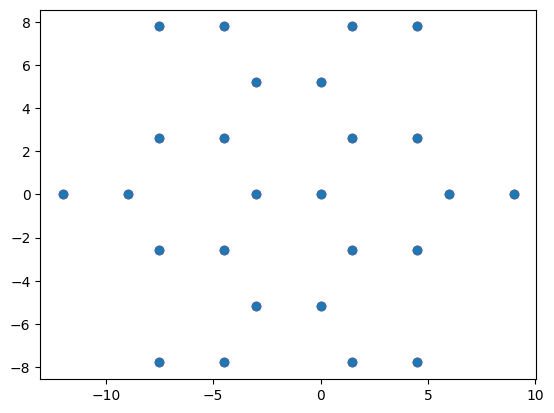

cc
Iteration 81: d-spacing = 20.97047, Kept 455 distances
ec
Iteration 81: d-spacing = 20.97047, Kept 324 distances
ce
Iteration 81: d-spacing = 20.97047, Kept 324 distances
ee
Iteration 81: d-spacing = 20.97047, Kept 212 distances


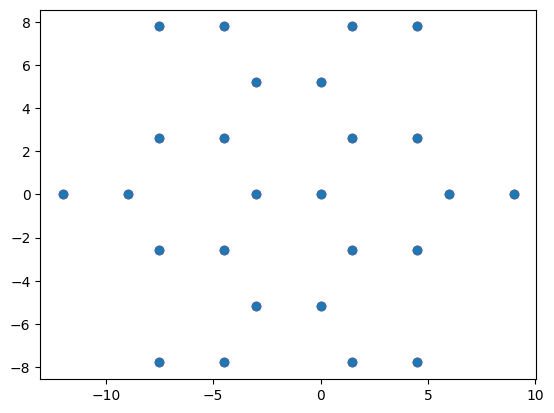

cc
Iteration 82: d-spacing = 21.112081, Kept 455 distances
ec
Iteration 82: d-spacing = 21.112081, Kept 324 distances
ce
Iteration 82: d-spacing = 21.112081, Kept 324 distances
ee
Iteration 82: d-spacing = 21.112081, Kept 212 distances


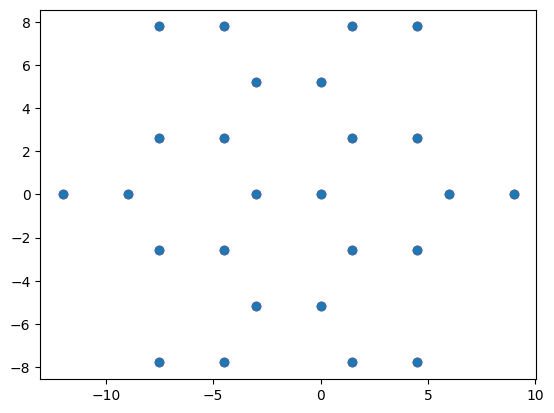

cc
Iteration 83: d-spacing = 21.253691, Kept 455 distances
ec
Iteration 83: d-spacing = 21.253691, Kept 324 distances
ce
Iteration 83: d-spacing = 21.253691, Kept 324 distances
ee
Iteration 83: d-spacing = 21.253691, Kept 212 distances


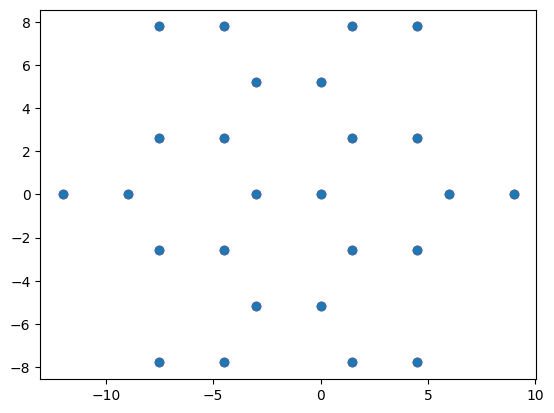

cc
Iteration 84: d-spacing = 21.395302, Kept 419 distances
ec
Iteration 84: d-spacing = 21.395302, Kept 300 distances
ce
Iteration 84: d-spacing = 21.395302, Kept 300 distances
ee
Iteration 84: d-spacing = 21.395302, Kept 196 distances


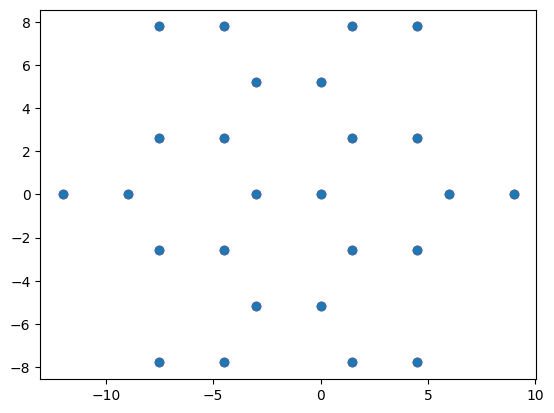

cc
Iteration 85: d-spacing = 21.536913, Kept 419 distances
ec
Iteration 85: d-spacing = 21.536913, Kept 300 distances
ce
Iteration 85: d-spacing = 21.536913, Kept 300 distances
ee
Iteration 85: d-spacing = 21.536913, Kept 196 distances


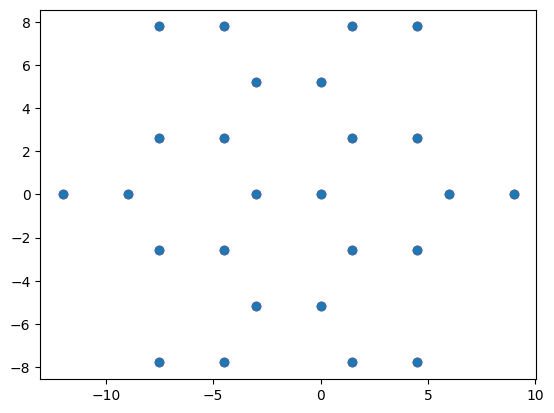

cc
Iteration 86: d-spacing = 21.678523, Kept 419 distances
ec
Iteration 86: d-spacing = 21.678523, Kept 300 distances
ce
Iteration 86: d-spacing = 21.678523, Kept 300 distances
ee
Iteration 86: d-spacing = 21.678523, Kept 196 distances


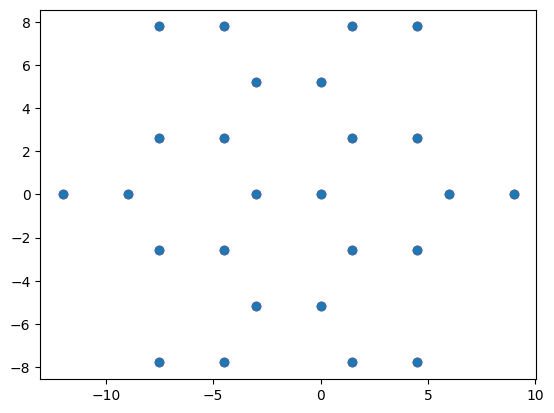

cc
Iteration 87: d-spacing = 21.820134, Kept 419 distances
ec
Iteration 87: d-spacing = 21.820134, Kept 300 distances
ce
Iteration 87: d-spacing = 21.820134, Kept 300 distances
ee
Iteration 87: d-spacing = 21.820134, Kept 196 distances


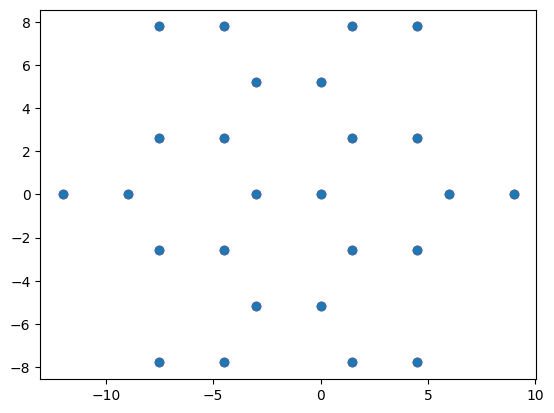

cc
Iteration 88: d-spacing = 21.961745, Kept 399 distances
ec
Iteration 88: d-spacing = 21.961745, Kept 284 distances
ce
Iteration 88: d-spacing = 21.961745, Kept 284 distances
ee
Iteration 88: d-spacing = 21.961745, Kept 196 distances


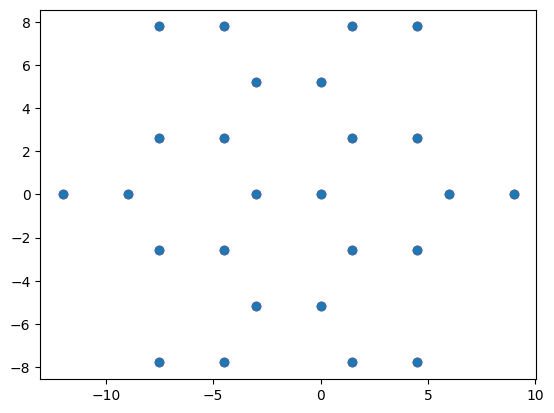

cc
Iteration 89: d-spacing = 22.103356, Kept 399 distances
ec
Iteration 89: d-spacing = 22.103356, Kept 272 distances
ce
Iteration 89: d-spacing = 22.103356, Kept 272 distances
ee
Iteration 89: d-spacing = 22.103356, Kept 196 distances


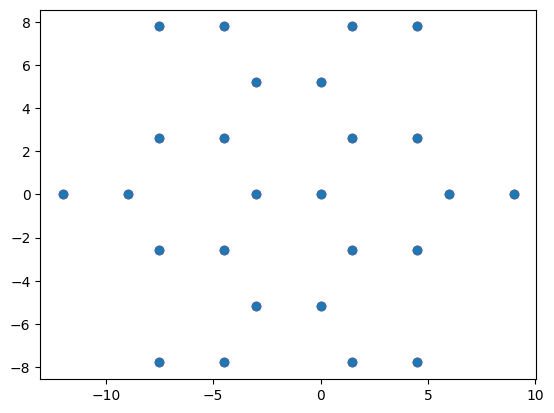

cc
Iteration 90: d-spacing = 22.244966, Kept 399 distances
ec
Iteration 90: d-spacing = 22.244966, Kept 272 distances
ce
Iteration 90: d-spacing = 22.244966, Kept 272 distances
ee
Iteration 90: d-spacing = 22.244966, Kept 196 distances


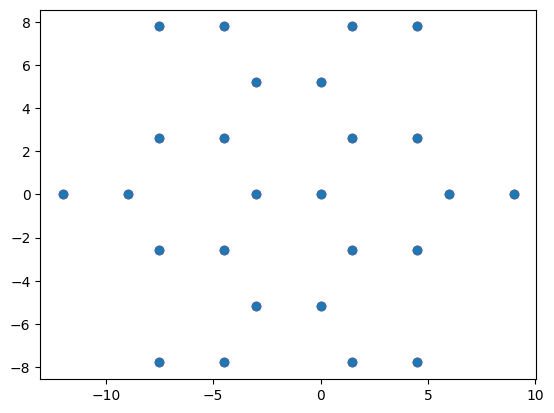

cc
Iteration 91: d-spacing = 22.386577, Kept 399 distances
ec
Iteration 91: d-spacing = 22.386577, Kept 272 distances
ce
Iteration 91: d-spacing = 22.386577, Kept 272 distances
ee
Iteration 91: d-spacing = 22.386577, Kept 196 distances


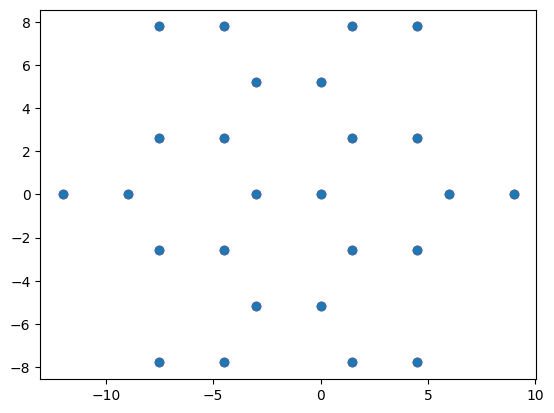

cc
Iteration 92: d-spacing = 22.528188, Kept 399 distances
ec
Iteration 92: d-spacing = 22.528188, Kept 272 distances
ce
Iteration 92: d-spacing = 22.528188, Kept 272 distances
ee
Iteration 92: d-spacing = 22.528188, Kept 196 distances


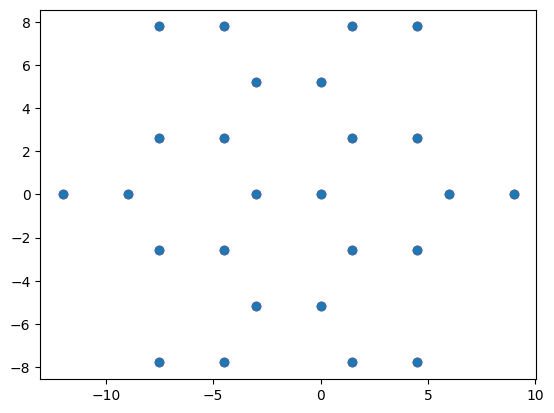

cc
Iteration 93: d-spacing = 22.669799, Kept 347 distances
ec
Iteration 93: d-spacing = 22.669799, Kept 228 distances
ce
Iteration 93: d-spacing = 22.669799, Kept 228 distances
ee
Iteration 93: d-spacing = 22.669799, Kept 180 distances


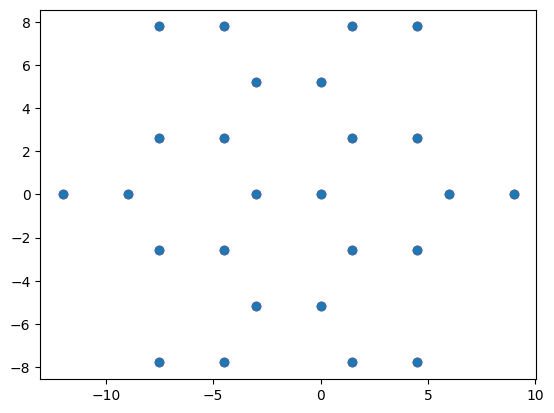

cc
Iteration 94: d-spacing = 22.811409, Kept 347 distances
ec
Iteration 94: d-spacing = 22.811409, Kept 216 distances
ce
Iteration 94: d-spacing = 22.811409, Kept 216 distances
ee
Iteration 94: d-spacing = 22.811409, Kept 180 distances


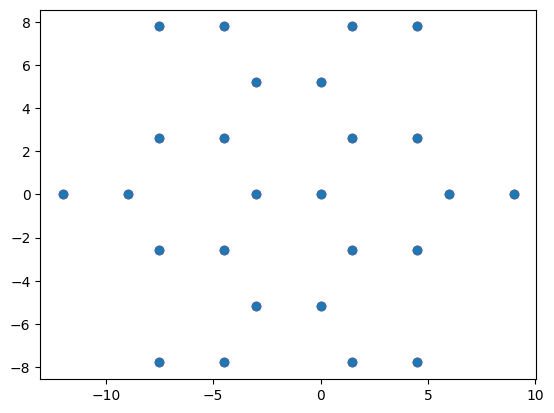

cc
Iteration 95: d-spacing = 22.95302, Kept 341 distances
ec
Iteration 95: d-spacing = 22.95302, Kept 216 distances
ce
Iteration 95: d-spacing = 22.95302, Kept 216 distances
ee
Iteration 95: d-spacing = 22.95302, Kept 168 distances


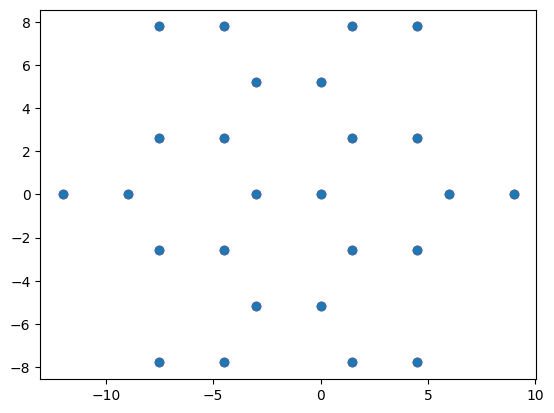

cc
Iteration 96: d-spacing = 23.094631, Kept 341 distances
ec
Iteration 96: d-spacing = 23.094631, Kept 216 distances
ce
Iteration 96: d-spacing = 23.094631, Kept 216 distances
ee
Iteration 96: d-spacing = 23.094631, Kept 168 distances


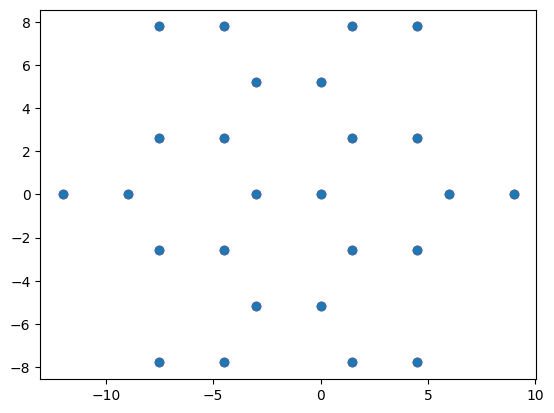

cc
Iteration 97: d-spacing = 23.236242, Kept 341 distances
ec
Iteration 97: d-spacing = 23.236242, Kept 216 distances
ce
Iteration 97: d-spacing = 23.236242, Kept 216 distances
ee
Iteration 97: d-spacing = 23.236242, Kept 168 distances


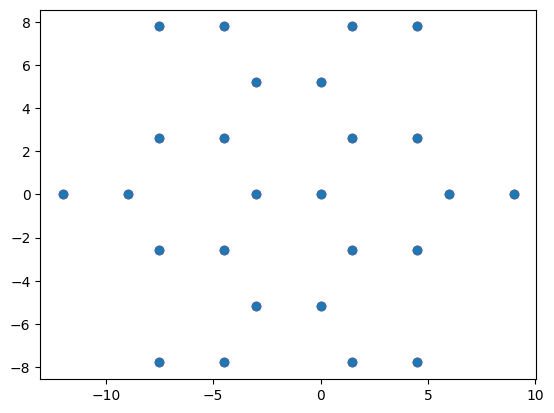

cc
Iteration 98: d-spacing = 23.377852, Kept 341 distances
ec
Iteration 98: d-spacing = 23.377852, Kept 206 distances
ce
Iteration 98: d-spacing = 23.377852, Kept 206 distances
ee
Iteration 98: d-spacing = 23.377852, Kept 156 distances


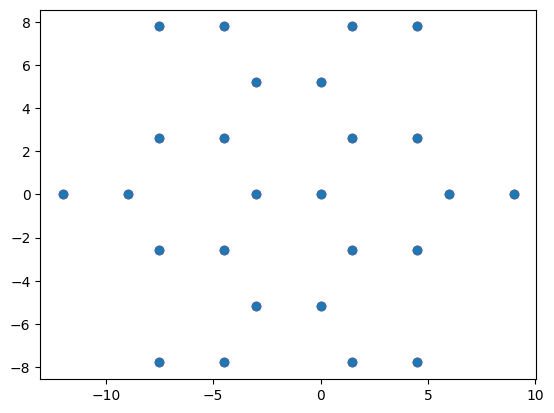

cc
Iteration 99: d-spacing = 23.519463, Kept 341 distances
ec
Iteration 99: d-spacing = 23.519463, Kept 206 distances
ce
Iteration 99: d-spacing = 23.519463, Kept 206 distances
ee
Iteration 99: d-spacing = 23.519463, Kept 156 distances


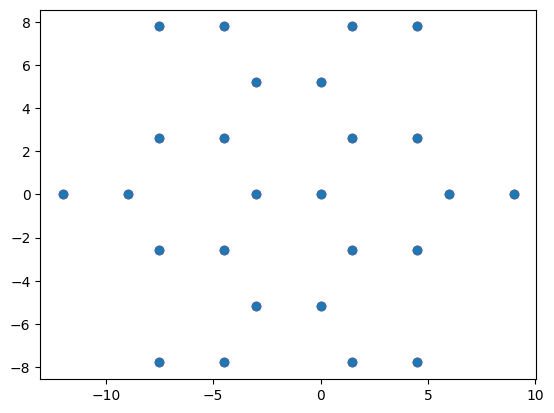

cc
Iteration 100: d-spacing = 23.661074, Kept 341 distances
ec
Iteration 100: d-spacing = 23.661074, Kept 206 distances
ce
Iteration 100: d-spacing = 23.661074, Kept 206 distances
ee
Iteration 100: d-spacing = 23.661074, Kept 156 distances


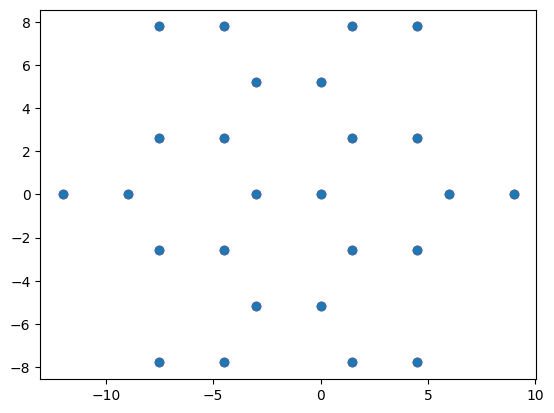

cc
Iteration 101: d-spacing = 23.802685, Kept 265 distances
ec
Iteration 101: d-spacing = 23.802685, Kept 174 distances
ce
Iteration 101: d-spacing = 23.802685, Kept 174 distances
ee
Iteration 101: d-spacing = 23.802685, Kept 132 distances


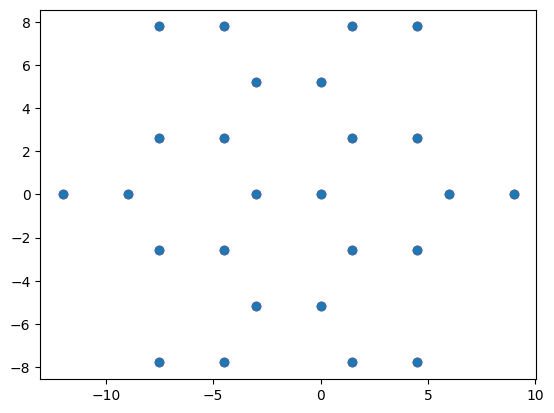

cc
Iteration 102: d-spacing = 23.944295, Kept 265 distances
ec
Iteration 102: d-spacing = 23.944295, Kept 174 distances
ce
Iteration 102: d-spacing = 23.944295, Kept 174 distances
ee
Iteration 102: d-spacing = 23.944295, Kept 132 distances


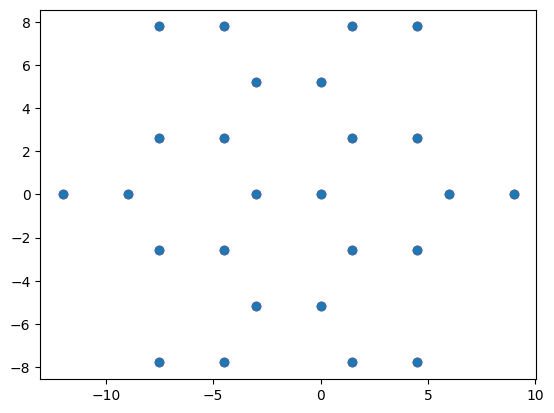

cc
Iteration 103: d-spacing = 24.085906, Kept 265 distances
ec
Iteration 103: d-spacing = 24.085906, Kept 162 distances
ce
Iteration 103: d-spacing = 24.085906, Kept 162 distances
ee
Iteration 103: d-spacing = 24.085906, Kept 132 distances


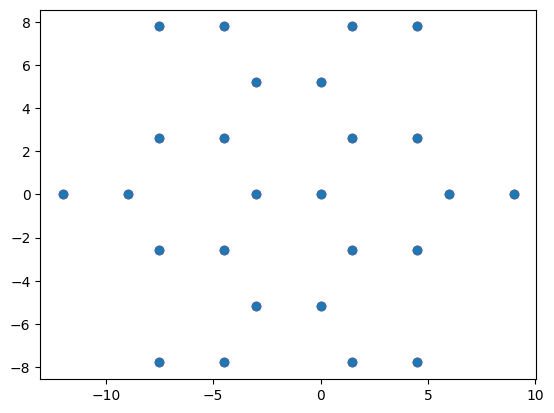

cc
Iteration 104: d-spacing = 24.227517, Kept 265 distances
ec
Iteration 104: d-spacing = 24.227517, Kept 162 distances
ce
Iteration 104: d-spacing = 24.227517, Kept 162 distances
ee
Iteration 104: d-spacing = 24.227517, Kept 132 distances


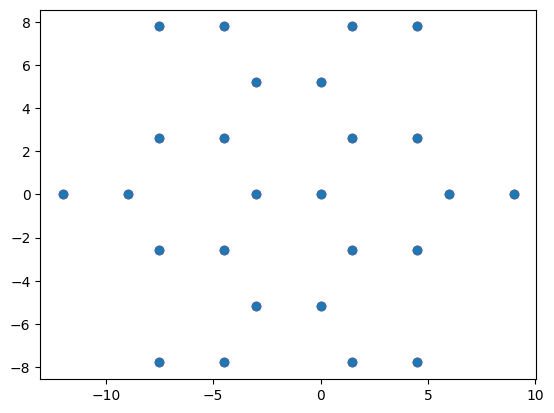

cc
Iteration 105: d-spacing = 24.369128, Kept 221 distances
ec
Iteration 105: d-spacing = 24.369128, Kept 140 distances
ce
Iteration 105: d-spacing = 24.369128, Kept 140 distances
ee
Iteration 105: d-spacing = 24.369128, Kept 132 distances


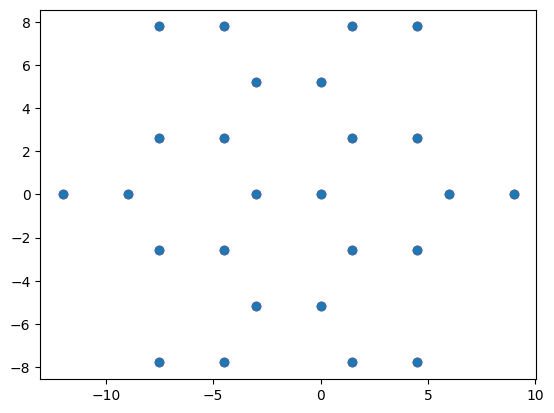

cc
Iteration 106: d-spacing = 24.510738, Kept 221 distances
ec
Iteration 106: d-spacing = 24.510738, Kept 132 distances
ce
Iteration 106: d-spacing = 24.510738, Kept 132 distances
ee
Iteration 106: d-spacing = 24.510738, Kept 116 distances


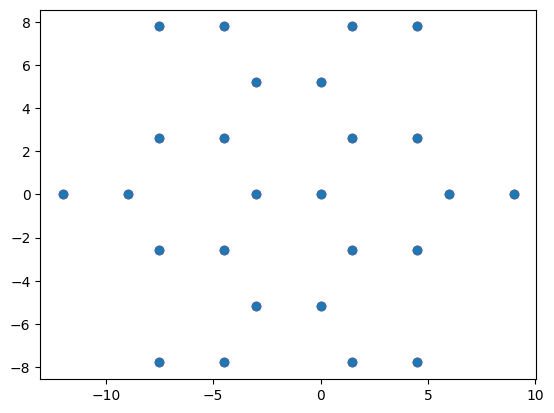

cc
Iteration 107: d-spacing = 24.652349, Kept 221 distances
ec
Iteration 107: d-spacing = 24.652349, Kept 132 distances
ce
Iteration 107: d-spacing = 24.652349, Kept 132 distances
ee
Iteration 107: d-spacing = 24.652349, Kept 116 distances


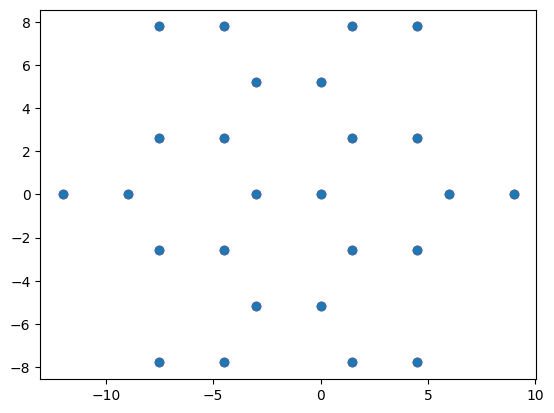

cc
Iteration 108: d-spacing = 24.79396, Kept 221 distances
ec
Iteration 108: d-spacing = 24.79396, Kept 132 distances
ce
Iteration 108: d-spacing = 24.79396, Kept 132 distances
ee
Iteration 108: d-spacing = 24.79396, Kept 92 distances


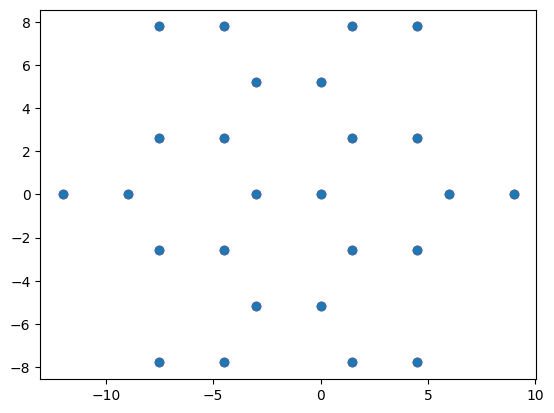

cc
Iteration 109: d-spacing = 24.93557, Kept 163 distances
ec
Iteration 109: d-spacing = 24.93557, Kept 116 distances
ce
Iteration 109: d-spacing = 24.93557, Kept 116 distances
ee
Iteration 109: d-spacing = 24.93557, Kept 60 distances


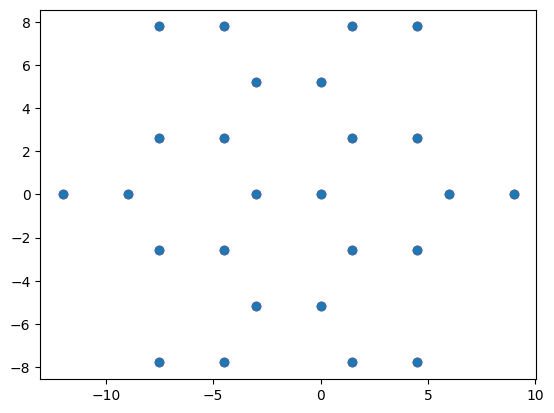

cc
Iteration 110: d-spacing = 25.077181, Kept 151 distances
ec
Iteration 110: d-spacing = 25.077181, Kept 108 distances
ce
Iteration 110: d-spacing = 25.077181, Kept 108 distances
ee
Iteration 110: d-spacing = 25.077181, Kept 60 distances


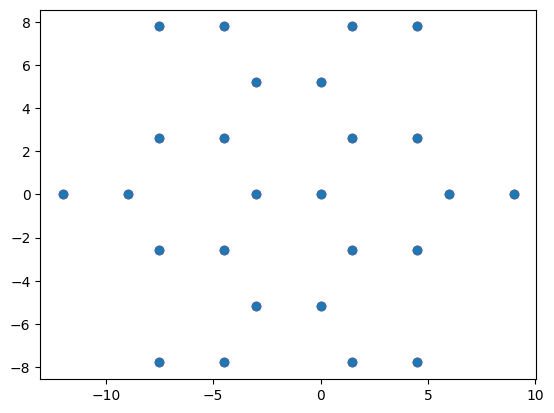

cc
Iteration 111: d-spacing = 25.218792, Kept 151 distances
ec
Iteration 111: d-spacing = 25.218792, Kept 108 distances
ce
Iteration 111: d-spacing = 25.218792, Kept 108 distances
ee
Iteration 111: d-spacing = 25.218792, Kept 60 distances


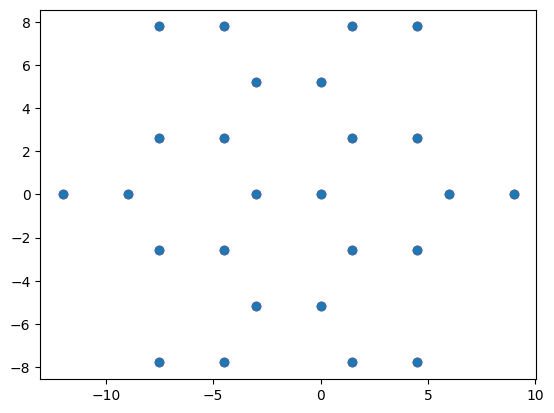

cc
Iteration 112: d-spacing = 25.360403, Kept 151 distances
ec
Iteration 112: d-spacing = 25.360403, Kept 108 distances
ce
Iteration 112: d-spacing = 25.360403, Kept 108 distances
ee
Iteration 112: d-spacing = 25.360403, Kept 60 distances


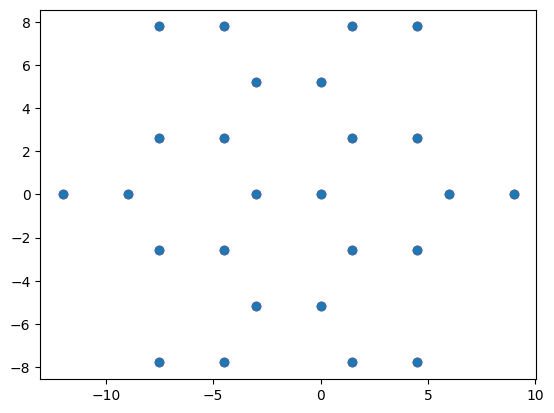

cc
Iteration 113: d-spacing = 25.502013, Kept 151 distances
ec
Iteration 113: d-spacing = 25.502013, Kept 108 distances
ce
Iteration 113: d-spacing = 25.502013, Kept 108 distances
ee
Iteration 113: d-spacing = 25.502013, Kept 60 distances


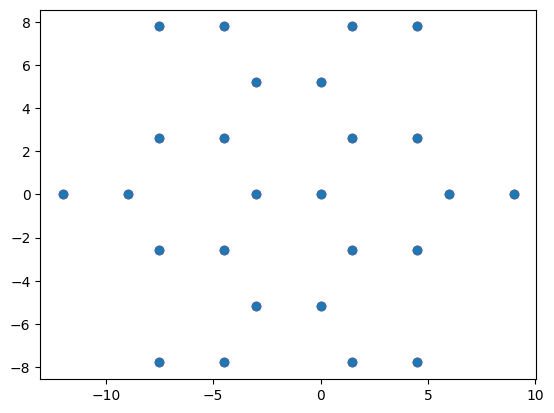

cc
Iteration 114: d-spacing = 25.643624, Kept 151 distances
ec
Iteration 114: d-spacing = 25.643624, Kept 108 distances
ce
Iteration 114: d-spacing = 25.643624, Kept 108 distances
ee
Iteration 114: d-spacing = 25.643624, Kept 60 distances


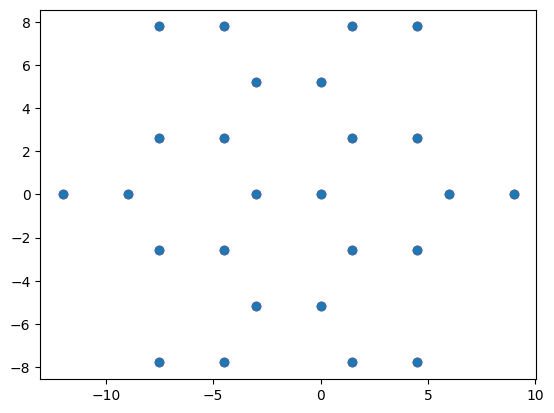

cc
Iteration 115: d-spacing = 25.785235, Kept 151 distances
ec
Iteration 115: d-spacing = 25.785235, Kept 108 distances
ce
Iteration 115: d-spacing = 25.785235, Kept 108 distances
ee
Iteration 115: d-spacing = 25.785235, Kept 60 distances


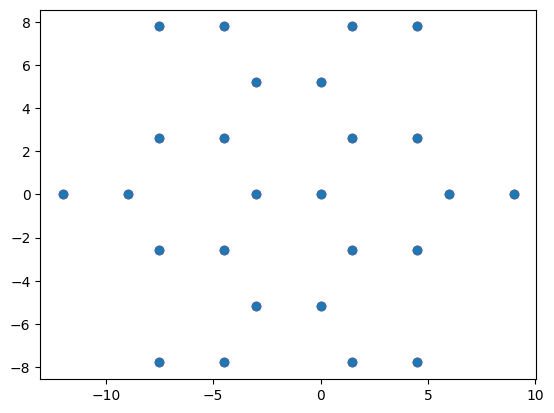

cc
Iteration 116: d-spacing = 25.926846, Kept 151 distances
ec
Iteration 116: d-spacing = 25.926846, Kept 108 distances
ce
Iteration 116: d-spacing = 25.926846, Kept 108 distances
ee
Iteration 116: d-spacing = 25.926846, Kept 60 distances


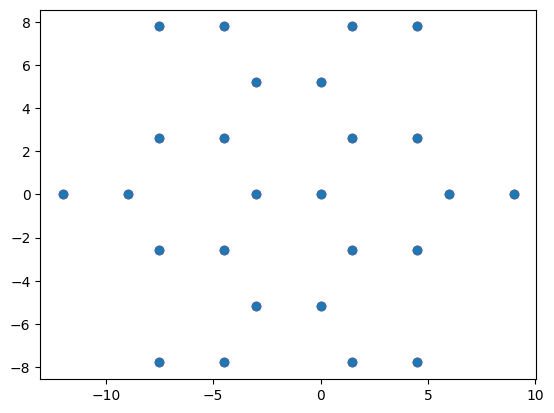

cc
Iteration 117: d-spacing = 26.068456, Kept 151 distances
ec
Iteration 117: d-spacing = 26.068456, Kept 108 distances
ce
Iteration 117: d-spacing = 26.068456, Kept 108 distances
ee
Iteration 117: d-spacing = 26.068456, Kept 60 distances


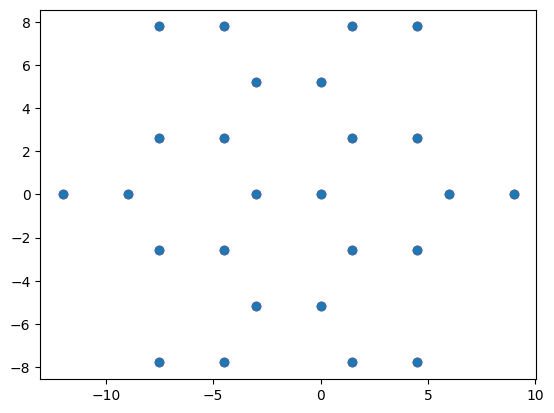

cc
Iteration 118: d-spacing = 26.210067, Kept 151 distances
ec
Iteration 118: d-spacing = 26.210067, Kept 108 distances
ce
Iteration 118: d-spacing = 26.210067, Kept 108 distances
ee
Iteration 118: d-spacing = 26.210067, Kept 60 distances


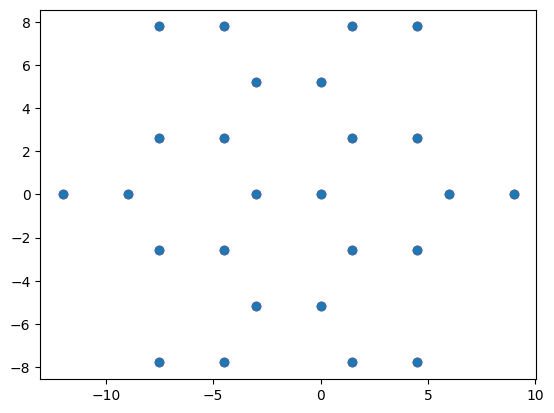

cc
Iteration 119: d-spacing = 26.351678, Kept 127 distances
ec
Iteration 119: d-spacing = 26.351678, Kept 84 distances
ce
Iteration 119: d-spacing = 26.351678, Kept 84 distances
ee
Iteration 119: d-spacing = 26.351678, Kept 60 distances


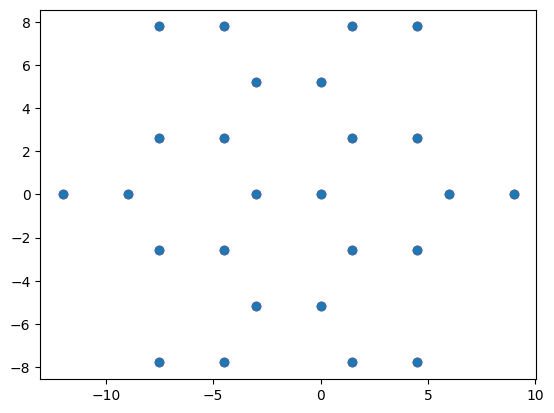

cc
Iteration 120: d-spacing = 26.493289, Kept 127 distances
ec
Iteration 120: d-spacing = 26.493289, Kept 84 distances
ce
Iteration 120: d-spacing = 26.493289, Kept 84 distances
ee
Iteration 120: d-spacing = 26.493289, Kept 60 distances


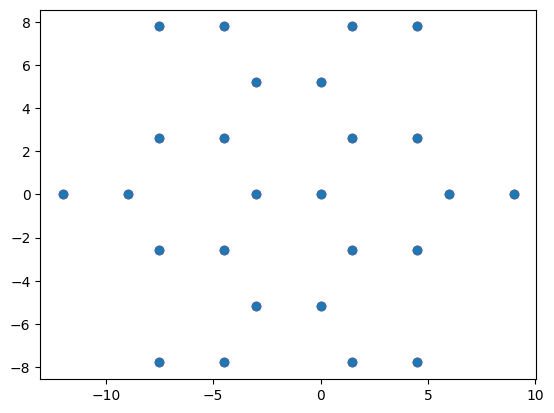

cc
Iteration 121: d-spacing = 26.634899, Kept 127 distances
ec
Iteration 121: d-spacing = 26.634899, Kept 84 distances
ce
Iteration 121: d-spacing = 26.634899, Kept 84 distances
ee
Iteration 121: d-spacing = 26.634899, Kept 60 distances


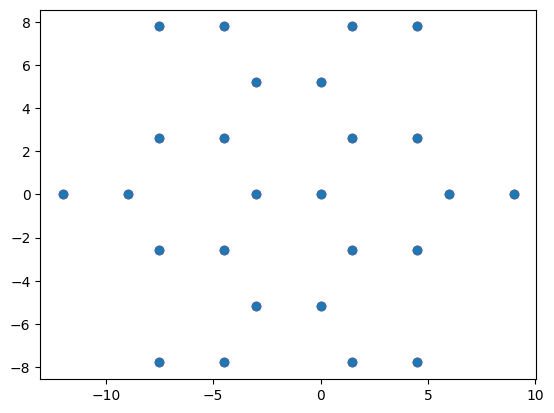

cc
Iteration 122: d-spacing = 26.77651, Kept 127 distances
ec
Iteration 122: d-spacing = 26.77651, Kept 72 distances
ce
Iteration 122: d-spacing = 26.77651, Kept 72 distances
ee
Iteration 122: d-spacing = 26.77651, Kept 60 distances


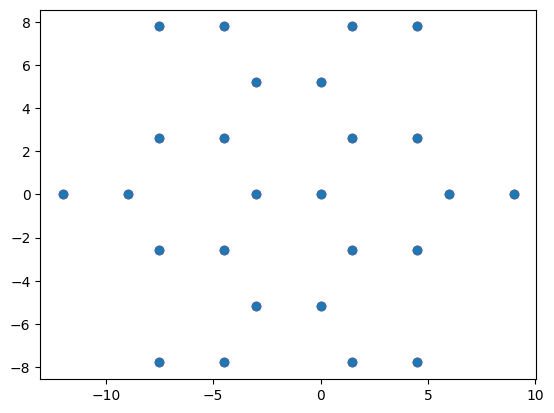

cc
Iteration 123: d-spacing = 26.918121, Kept 127 distances
ec
Iteration 123: d-spacing = 26.918121, Kept 72 distances
ce
Iteration 123: d-spacing = 26.918121, Kept 72 distances
ee
Iteration 123: d-spacing = 26.918121, Kept 60 distances


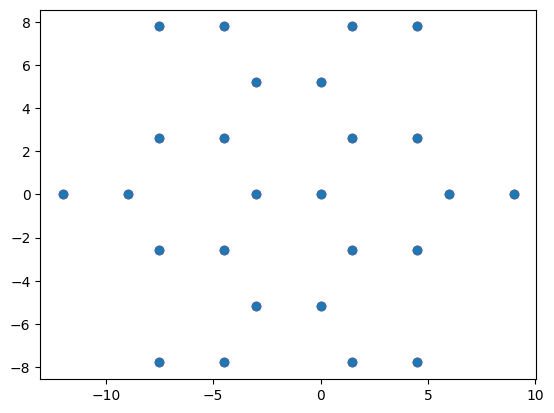

cc
Iteration 124: d-spacing = 27.059732, Kept 127 distances
ec
Iteration 124: d-spacing = 27.059732, Kept 72 distances
ce
Iteration 124: d-spacing = 27.059732, Kept 72 distances
ee
Iteration 124: d-spacing = 27.059732, Kept 60 distances


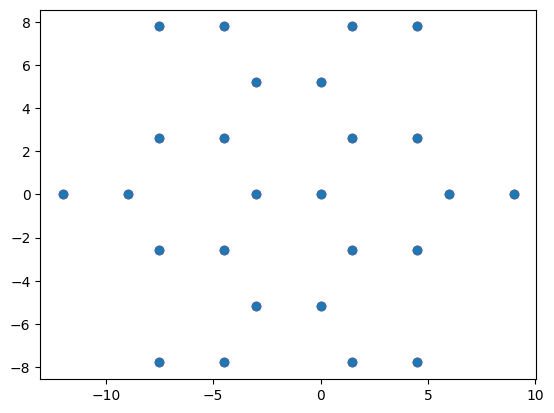

cc
Iteration 125: d-spacing = 27.201342, Kept 127 distances
ec
Iteration 125: d-spacing = 27.201342, Kept 72 distances
ce
Iteration 125: d-spacing = 27.201342, Kept 72 distances
ee
Iteration 125: d-spacing = 27.201342, Kept 60 distances


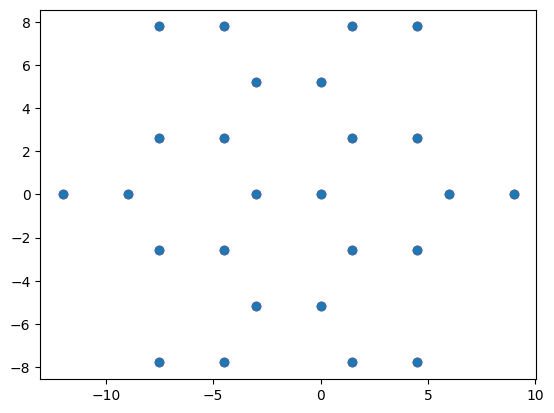

cc
Iteration 126: d-spacing = 27.342953, Kept 127 distances
ec
Iteration 126: d-spacing = 27.342953, Kept 72 distances
ce
Iteration 126: d-spacing = 27.342953, Kept 72 distances
ee
Iteration 126: d-spacing = 27.342953, Kept 60 distances


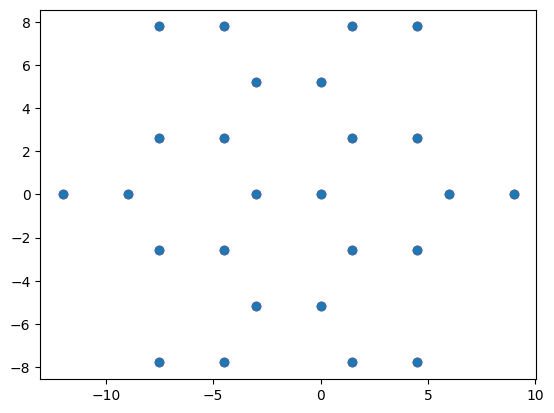

cc
Iteration 127: d-spacing = 27.484564, Kept 127 distances
ec
Iteration 127: d-spacing = 27.484564, Kept 66 distances
ce
Iteration 127: d-spacing = 27.484564, Kept 66 distances
ee
Iteration 127: d-spacing = 27.484564, Kept 48 distances


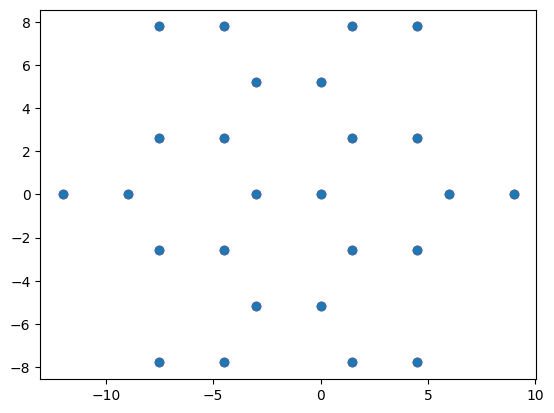

cc
Iteration 128: d-spacing = 27.626174, Kept 127 distances
ec
Iteration 128: d-spacing = 27.626174, Kept 66 distances
ce
Iteration 128: d-spacing = 27.626174, Kept 66 distances
ee
Iteration 128: d-spacing = 27.626174, Kept 48 distances


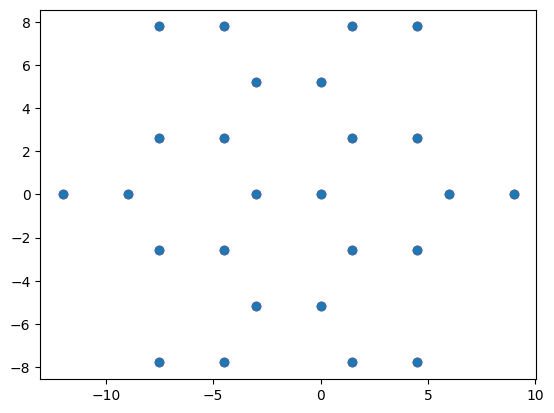

cc
Iteration 129: d-spacing = 27.767785, Kept 127 distances
ec
Iteration 129: d-spacing = 27.767785, Kept 66 distances
ce
Iteration 129: d-spacing = 27.767785, Kept 66 distances
ee
Iteration 129: d-spacing = 27.767785, Kept 48 distances


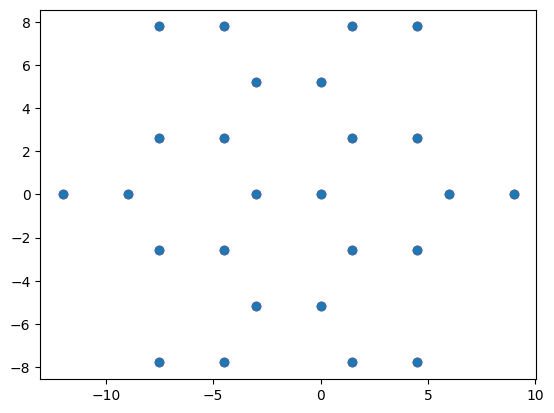

cc
Iteration 130: d-spacing = 27.909396, Kept 127 distances
ec
Iteration 130: d-spacing = 27.909396, Kept 66 distances
ce
Iteration 130: d-spacing = 27.909396, Kept 66 distances
ee
Iteration 130: d-spacing = 27.909396, Kept 48 distances


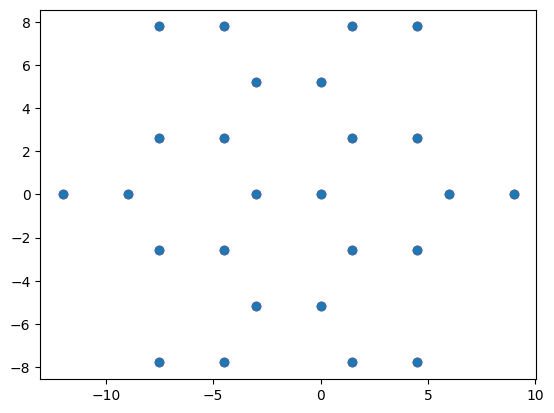

cc
Iteration 131: d-spacing = 28.051007, Kept 127 distances
ec
Iteration 131: d-spacing = 28.051007, Kept 54 distances
ce
Iteration 131: d-spacing = 28.051007, Kept 54 distances
ee
Iteration 131: d-spacing = 28.051007, Kept 48 distances


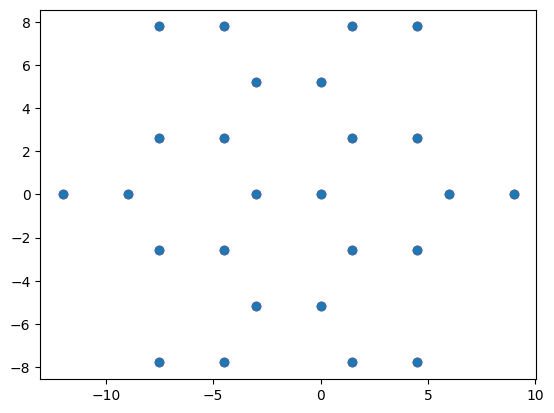

cc
Iteration 132: d-spacing = 28.192617, Kept 97 distances
ec
Iteration 132: d-spacing = 28.192617, Kept 48 distances
ce
Iteration 132: d-spacing = 28.192617, Kept 48 distances
ee
Iteration 132: d-spacing = 28.192617, Kept 36 distances


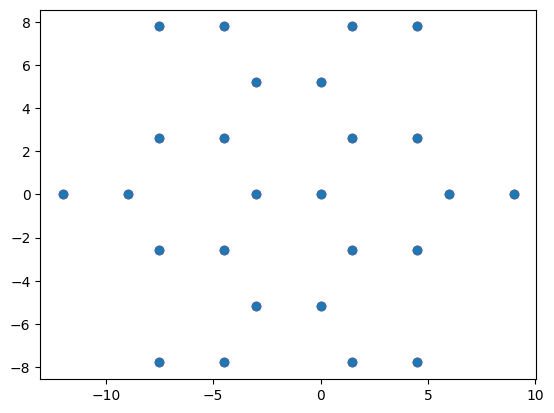

cc
Iteration 133: d-spacing = 28.334228, Kept 97 distances
ec
Iteration 133: d-spacing = 28.334228, Kept 48 distances
ce
Iteration 133: d-spacing = 28.334228, Kept 48 distances
ee
Iteration 133: d-spacing = 28.334228, Kept 36 distances


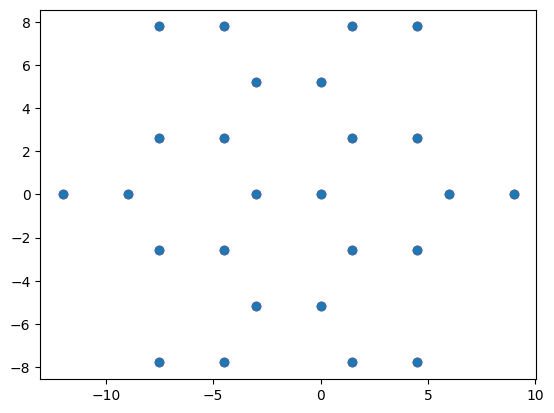

cc
Iteration 134: d-spacing = 28.475839, Kept 97 distances
ec
Iteration 134: d-spacing = 28.475839, Kept 48 distances
ce
Iteration 134: d-spacing = 28.475839, Kept 48 distances
ee
Iteration 134: d-spacing = 28.475839, Kept 36 distances


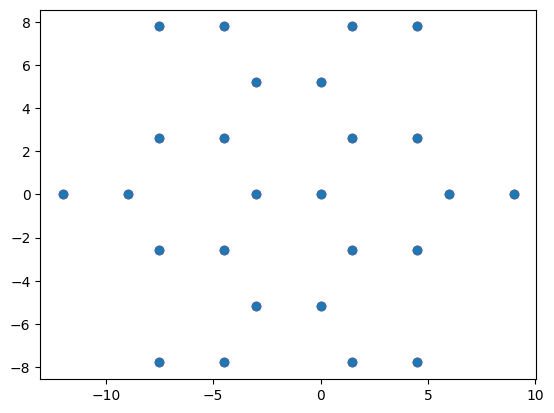

cc
Iteration 135: d-spacing = 28.61745, Kept 97 distances
ec
Iteration 135: d-spacing = 28.61745, Kept 48 distances
ce
Iteration 135: d-spacing = 28.61745, Kept 48 distances
ee
Iteration 135: d-spacing = 28.61745, Kept 36 distances


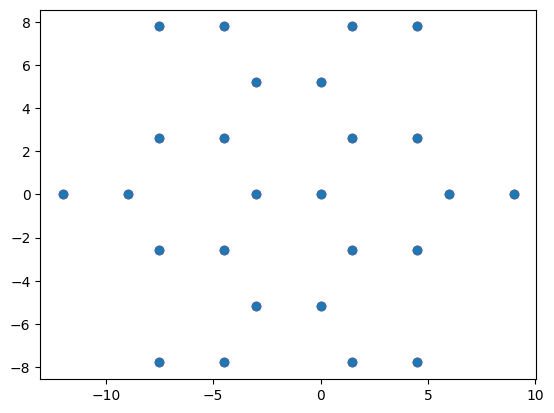

cc
Iteration 136: d-spacing = 28.75906, Kept 97 distances
ec
Iteration 136: d-spacing = 28.75906, Kept 48 distances
ce
Iteration 136: d-spacing = 28.75906, Kept 48 distances
ee
Iteration 136: d-spacing = 28.75906, Kept 36 distances


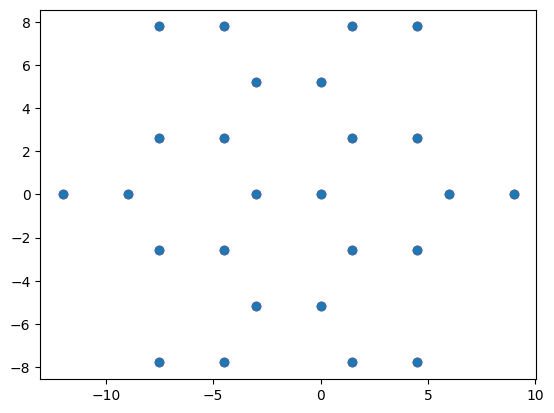

cc
Iteration 137: d-spacing = 28.900671, Kept 61 distances
ec
Iteration 137: d-spacing = 28.900671, Kept 36 distances
ce
Iteration 137: d-spacing = 28.900671, Kept 36 distances
ee
Iteration 137: d-spacing = 28.900671, Kept 36 distances


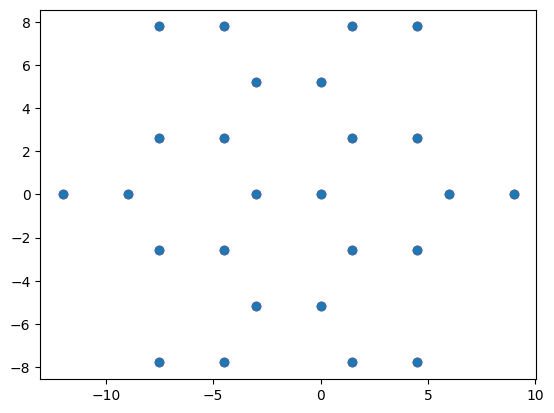

cc
Iteration 138: d-spacing = 29.042282, Kept 61 distances
ec
Iteration 138: d-spacing = 29.042282, Kept 36 distances
ce
Iteration 138: d-spacing = 29.042282, Kept 36 distances
ee
Iteration 138: d-spacing = 29.042282, Kept 36 distances


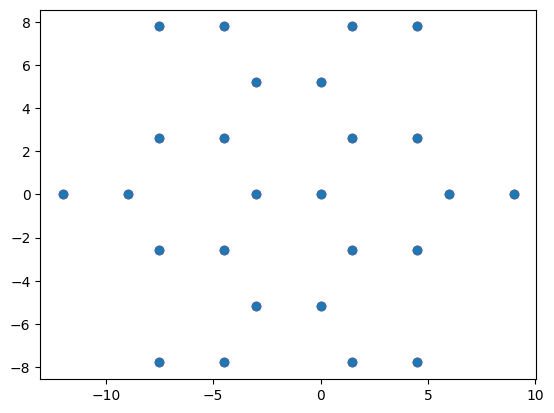

cc
Iteration 139: d-spacing = 29.183893, Kept 61 distances
ec
Iteration 139: d-spacing = 29.183893, Kept 24 distances
ce
Iteration 139: d-spacing = 29.183893, Kept 24 distances
ee
Iteration 139: d-spacing = 29.183893, Kept 36 distances


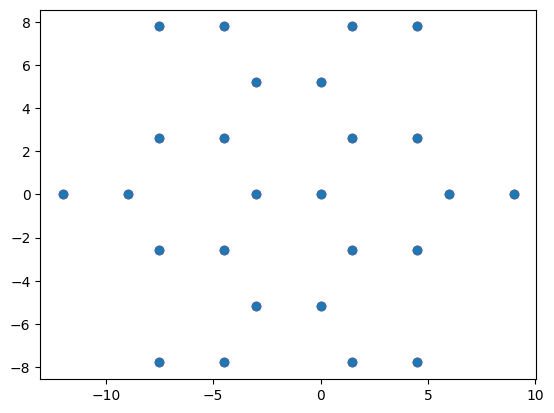

cc
Iteration 140: d-spacing = 29.325503, Kept 61 distances
ec
Iteration 140: d-spacing = 29.325503, Kept 24 distances
ce
Iteration 140: d-spacing = 29.325503, Kept 24 distances
ee
Iteration 140: d-spacing = 29.325503, Kept 36 distances


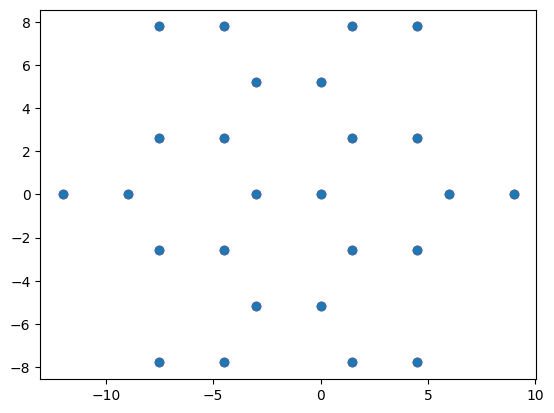

cc
Iteration 141: d-spacing = 29.467114, Kept 61 distances
ec
Iteration 141: d-spacing = 29.467114, Kept 24 distances
ce
Iteration 141: d-spacing = 29.467114, Kept 24 distances
ee
Iteration 141: d-spacing = 29.467114, Kept 36 distances


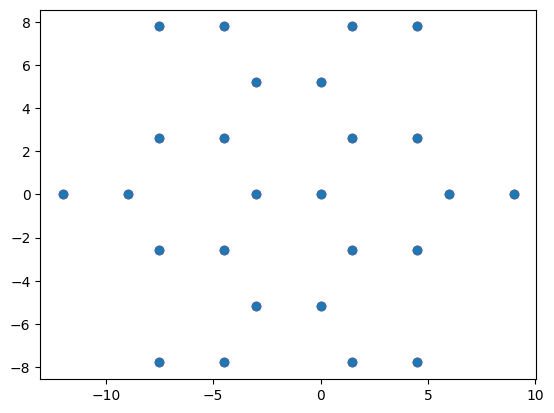

cc
Iteration 142: d-spacing = 29.608725, Kept 61 distances
ec
Iteration 142: d-spacing = 29.608725, Kept 24 distances
ce
Iteration 142: d-spacing = 29.608725, Kept 24 distances
ee
Iteration 142: d-spacing = 29.608725, Kept 36 distances


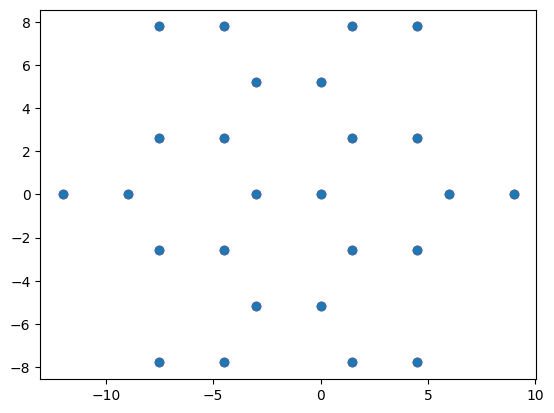

cc
Iteration 143: d-spacing = 29.750336, Kept 61 distances
ec
Iteration 143: d-spacing = 29.750336, Kept 24 distances
ce
Iteration 143: d-spacing = 29.750336, Kept 24 distances
ee
Iteration 143: d-spacing = 29.750336, Kept 12 distances


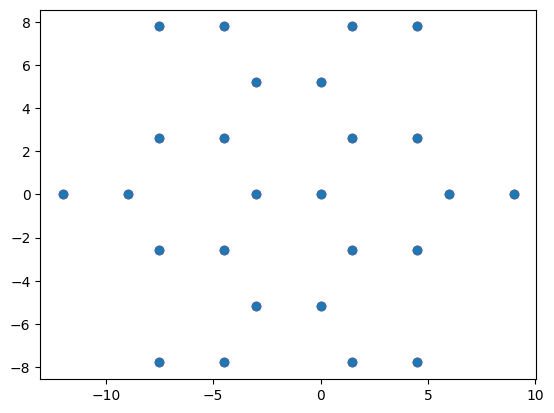

cc
Iteration 144: d-spacing = 29.891946, Kept 61 distances
ec
Iteration 144: d-spacing = 29.891946, Kept 24 distances
ce
Iteration 144: d-spacing = 29.891946, Kept 24 distances
ee
Iteration 144: d-spacing = 29.891946, Kept 12 distances


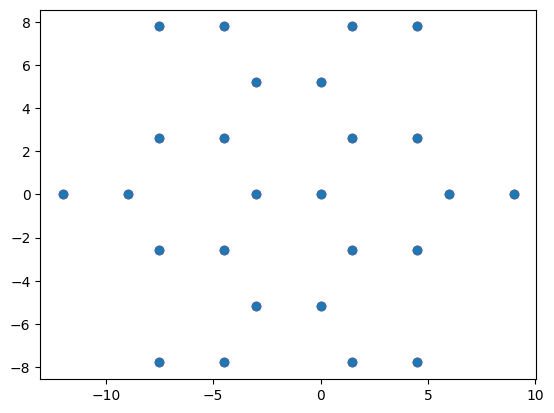

cc
Iteration 145: d-spacing = 30.033557, Kept 13 distances
ec
Iteration 145: d-spacing = 30.033557, Kept 6 distances
ce
Iteration 145: d-spacing = 30.033557, Kept 6 distances
ee
Iteration 145: d-spacing = 30.033557, Kept 12 distances


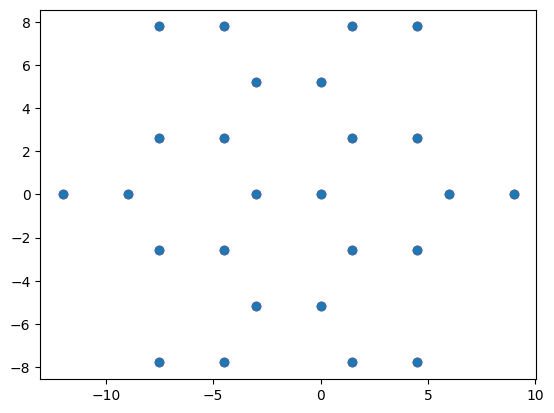

cc
Iteration 146: d-spacing = 30.175168, Kept 13 distances
ec
Iteration 146: d-spacing = 30.175168, Kept 6 distances
ce
Iteration 146: d-spacing = 30.175168, Kept 6 distances
ee
Iteration 146: d-spacing = 30.175168, Kept 12 distances


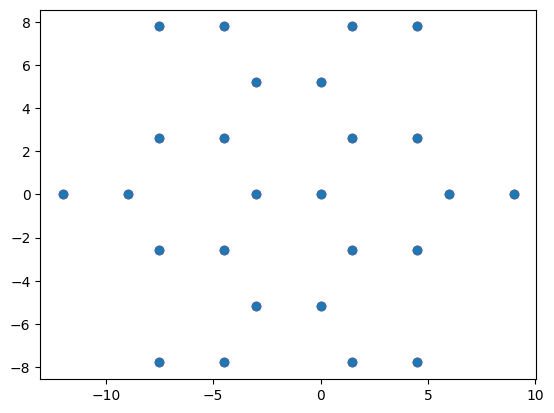

cc
Iteration 147: d-spacing = 30.316779, Kept 13 distances
ec
Iteration 147: d-spacing = 30.316779, Kept 0 distances
ce
Iteration 147: d-spacing = 30.316779, Kept 0 distances
ee
Iteration 147: d-spacing = 30.316779, Kept 12 distances


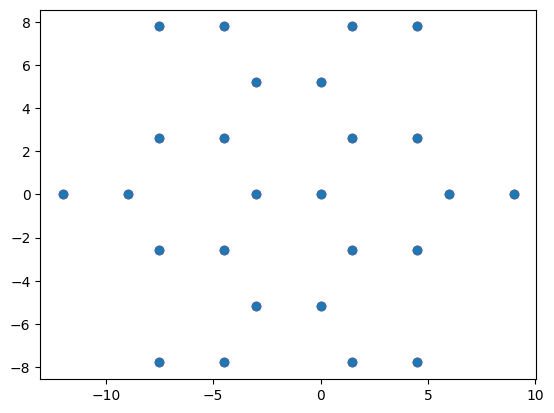

cc
Iteration 148: d-spacing = 30.458389, Kept 0 distances
ec
Iteration 148: d-spacing = 30.458389, Kept 0 distances
ce
Iteration 148: d-spacing = 30.458389, Kept 0 distances
ee
Iteration 148: d-spacing = 30.458389, Kept 0 distances


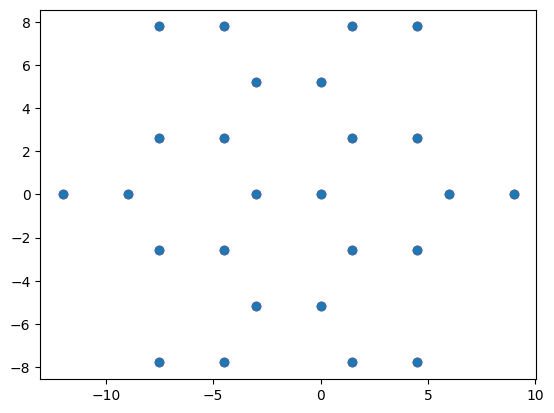

cc
Iteration 149: d-spacing = 30.6, Kept 0 distances
ec
Iteration 149: d-spacing = 30.6, Kept 0 distances
ce
Iteration 149: d-spacing = 30.6, Kept 0 distances
ee
Iteration 149: d-spacing = 30.6, Kept 0 distances
⚠ Missing in .out file: set()
⚠ Missing in .npy file: set()
d-spacing: 9.5, Number of distances: 676
d-spacing: 9.64161, Number of distances: 676
d-spacing: 9.78322, Number of distances: 676
d-spacing: 9.92483, Number of distances: 676
d-spacing: 10.06644, Number of distances: 676
⚠ Missing in .out file: set()
⚠ Missing in .npy file: set()
d-spacing: 9.5, Number of distances: 616
d-spacing: 9.64161, Number of distances: 616
d-spacing: 9.78322, Number of distances: 616
d-spacing: 9.92483, Number of distances: 616
d-spacing: 10.06644, Number of distances: 616
⚠ Missing in .out file: set()
⚠ Missing in .npy file: set()
d-spacing: 9.5, Number of distances: 616
d-spacing: 9.64161, Number of distances: 616
d-spacing: 9.78322, Number of distances: 616
d-spacing: 9.92483, Number of dis

In [79]:
os.chdir('/Volumes/Work/SecondProject/LastVersion/Prepration_2/Face-to-Face/1')
f_Stack=np.genfromtxt('dspacing_PMF.out', dtype=float,skip_header=0,skip_footer=0)
sorted_indices = np.argsort(f_Stack[:, 0])
f_Stack = f_Stack[sorted_indices]
z_S = f_Stack[:, 0]

plt.scatter(f_Stack[:, 0], f_Stack[:, 1])
plt.show()
# S_CentralPlateMirr=S_CentralPlate.copy()

# S_EdgePlateMirr=S_EdgePlate.copy()


cen_dis = {}
ed_cen_dis = {}
ed_dis = {}
cen_ed_dis = {}
        



for i, spacing in enumerate(z_S):

    CentralPlateMirr = S_CentralPlateMirr.copy()
    CentralPlateMirr[:,2] += spacing 
    plt.scatter(CentralPlateMirr[:, 0],CentralPlateMirr[:, 1], color = 'red')
    plt.scatter(S_CentralPlate[:, 0],S_CentralPlate[:, 1])
    plt.show()
    dist_matrix_cc = distance.cdist(CentralPlateMirr, S_CentralPlate)
    final_distances_cc = dist_matrix_cc[dist_matrix_cc <= 25]   
    cen_dis[round(spacing, 5)] = final_distances_cc
    print('cc')
    print(f"Iteration {i}: d-spacing = {spacing}, Kept {len(final_distances_cc)} distances")

####    
    EdgePlateMirr=S_EdgePlateMirr.copy()
    EdgePlateMirr[:,2] += spacing 
    
#     plt.scatter(EdgePlateMirr[:, 0],EdgePlateMirr[:, 1])
#     plt.scatter(S_CentralPlate[:, 0],S_CentralPlate[:, 1])
#     plt.show()
    

    
    dist_matrix_ec = distance.cdist(EdgePlateMirr, S_CentralPlate)
    final_distances_ec = dist_matrix_ec[dist_matrix_ec <= 25]   
    ed_cen_dis[round(spacing, 5)] = final_distances_ec
    print('ec')
    print(f"Iteration {i}: d-spacing = {spacing}, Kept {len(final_distances_ec)} distances")

####    
    CentralPlateMirr = S_CentralPlateMirr.copy()
    CentralPlateMirr[:,2] += spacing 

#     plt.scatter(CentralPlateMirr[:, 0],CentralPlateMirr[:, 1])
#     plt.scatter(S_EdgePlate[:, 0],S_EdgePlate[:, 1], color = 'red')
#     plt.show()
    dist_matrix_ce = distance.cdist(CentralPlateMirr, S_EdgePlate)
    final_distances_ce = dist_matrix_ce[dist_matrix_ce <= 25]   
    cen_ed_dis[round(spacing, 5)] = final_distances_ce
    print('ce')
    print(f"Iteration {i}: d-spacing = {spacing}, Kept {len(final_distances_ce)} distances")

####    
    
        
    EdgePlateMirr=S_EdgePlateMirr.copy()
    EdgePlateMirr[:,2] += spacing  
    
#     plt.scatter(EdgePlateMirr[:, 0],EdgePlateMirr[:, 1], color = 'red')
#     plt.scatter(S_EdgePlate[:, 0],S_EdgePlate[:, 1])
#     plt.show()
    dist_matrix_ee = distance.cdist(EdgePlateMirr, S_EdgePlate)
    final_distances_ee = dist_matrix_ee[dist_matrix_ee <= 25]   
    ed_dis[round(spacing, 5)] = final_distances_ee
    print('ee')
    print(f"Iteration {i}: d-spacing = {spacing}, Kept {len(final_distances_ee)} distances")
    
    
    
    
# Save using .npy for structured storage
output_file_npy = "/Volumes/Work/SecondProject/LastVersion/Prepration_2/Face-to-Face/1/PairDis_1_CC.npy"
np.save(output_file_npy, cen_dis, allow_pickle=True)

# print(f"✅ Saved data in .npy format: {output_file_npy}")

# Load and check stored distances
loaded_data = np.load(output_file_npy, allow_pickle=True).item()

# Compare d-spacing values between .out and .npy
d_spacing_out = {round(x, 5) for x in f_Stack[:, 0]}
d_spacing_npy = {round(x, 5) for x in loaded_data.keys()}

missing_in_out = d_spacing_npy - d_spacing_out
missing_in_npy = d_spacing_out - d_spacing_npy

print(f"⚠ Missing in .out file: {missing_in_out}")
print(f"⚠ Missing in .npy file: {missing_in_npy}")

# Check stored distances for a specific d-spacing
for key in list(loaded_data.keys())[:5]:  # Show first 5 keys
    print(f"d-spacing: {key}, Number of distances: {len(loaded_data[key])}")
    
# Save using .npy for structured storage
output_file_npy = "/Volumes/Work/SecondProject/LastVersion/Prepration_2/Face-to-Face/1/PairDis_1_EC.npy"
np.save(output_file_npy, ed_cen_dis, allow_pickle=True)

# print(f"✅ Saved data in .npy format: {output_file_npy}")

# Load and check stored distances
loaded_data = np.load(output_file_npy, allow_pickle=True).item()

# Compare d-spacing values between .out and .npy
d_spacing_out = {round(x, 5) for x in f_Stack[:, 0]}
d_spacing_npy = {round(x, 5) for x in loaded_data.keys()}

missing_in_out = d_spacing_npy - d_spacing_out
missing_in_npy = d_spacing_out - d_spacing_npy

print(f"⚠ Missing in .out file: {missing_in_out}")
print(f"⚠ Missing in .npy file: {missing_in_npy}")

# Check stored distances for a specific d-spacing
for key in list(loaded_data.keys())[:5]:  # Show first 5 keys
    print(f"d-spacing: {key}, Number of distances: {len(loaded_data[key])}")

    
# Save using .npy for structured storage
output_file_npy = "/Volumes/Work/SecondProject/LastVersion/Prepration_2/Face-to-Face/1/PairDis_1_CE.npy"
np.save(output_file_npy, cen_ed_dis, allow_pickle=True)

# print(f"✅ Saved data in .npy format: {output_file_npy}")

# Load and check stored distances
loaded_data = np.load(output_file_npy, allow_pickle=True).item()

# Compare d-spacing values between .out and .npy
d_spacing_out = {round(x, 5) for x in f_Stack[:, 0]}
d_spacing_npy = {round(x, 5) for x in loaded_data.keys()}

missing_in_out = d_spacing_npy - d_spacing_out
missing_in_npy = d_spacing_out - d_spacing_npy

print(f"⚠ Missing in .out file: {missing_in_out}")
print(f"⚠ Missing in .npy file: {missing_in_npy}")

# Check stored distances for a specific d-spacing
for key in list(loaded_data.keys())[:5]:  # Show first 5 keys
    print(f"d-spacing: {key}, Number of distances: {len(loaded_data[key])}")
    
    
# Save using .npy for structured storage
output_file_npy = "/Volumes/Work/SecondProject/LastVersion/Prepration_2/Face-to-Face/1/PairDis_1_EE.npy"
np.save(output_file_npy, ed_dis, allow_pickle=True)

# print(f"✅ Saved data in .npy format: {output_file_npy}")

# Load and check stored distances
loaded_data = np.load(output_file_npy, allow_pickle=True).item()

# Compare d-spacing values between .out and .npy
d_spacing_out = {round(x, 5) for x in f_Stack[:, 0]}
d_spacing_npy = {round(x, 5) for x in loaded_data.keys()}

missing_in_out = d_spacing_npy - d_spacing_out
missing_in_npy = d_spacing_out - d_spacing_npy

print(f"⚠ Missing in .out file: {missing_in_out}")
print(f"⚠ Missing in .npy file: {missing_in_npy}")

# Check stored distances for a specific d-spacing
for key in list(loaded_data.keys())[:5]:  # Show first 5 keys
    print(f"d-spacing: {key}, Number of distances: {len(loaded_data[key])}")
    

    